# Civic Complaint Data Collection and Label Preparation

This notebook explores the 2019–2022 complaint export, maps the source labels to CivicSense categories, reviews ambiguous records, and prepares English and multilingual labelled data. Manual review CSV files are part of the workflow: complete them before running the cells that apply their labels. 

> Run the notebook from top to bottom when rebuilding the intermediate files. Existing outputs are retained here as a record of the completed analysis.


## 1. Inspect the source complaint dataset

Load the raw export and check its structure, missing values, duplicates, labels, and representative complaint text.


In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:
DATA_PATH = Path("../data/raw/ichangemycity_complaints_2019_2022.csv")

In [4]:
df = pd.read_csv(DATA_PATH, encoding="latin1")

In [5]:
df.head()

,created_at,ward_id,title,description,sub_category_id,civic_agency_id,location,address,latitude,longitude,ward_title,category_id,category_title,sub_category_title,civic_agency_title,complaint_status_title,comment_count
0,1-1-2019 06:33,22,Govt Road is encroached with knowledge of offi...,Govt Road is encroached by Private buildings i...,162,10.0,"9Th Cross St, Hanumanthappa Layout, Sultanpaly...",Opposite S M Food Palace,13.031806,77.605437,Vishwanath Nagenahalli,382.0,Community Infrastructure and Services,Government Land/Property Encroachment,BBMP,Resolved,6
1,1-1-2019 09:59,27,Money menace is a huge problem with residents ...,Money menace is a huge problem with residents ...,42,NaN,"2, 1St Cross Rd, Chikka Banaswadi, Ombr Layout...",NaN,13.006506,77.644485,Banasavadi,9.0,Others,Others,NaN,Open,0
2,1-1-2019 12:57,17,Showing old owner name in online property tax ...,My property SAS base app no 1600800634 New Pid...,148,10.0,"No.18 19Th Cross, 19, 19Th Cross, Muthyala Nag...",J P Park,13.038634,77.551505,J P Park,1.0,Certificates,Property Tax,BBMP,Resolved,1
3,1-1-2019 13:09,161,Extremely dangerous BTP barrier in the middle ...,Extremely dangerous BTP barrier in the middle ...,67,10.0,"Anjaneya Nagar, Ittamadu, Banashankari 3Rd Sta...",NaN,12.926871,77.544714,Hosakerehalli,15.0,"Mobility - Roads, Footpaths and Infrastructure",Tarring Or Asphalting Of Existing Road,BBMP,Resolved,2
4,1-1-2019 14:41,176,No water supply,Lat few days there is no proper water supply i...,182,2.0,"27Th Main Rd, Btm 2Nd Stage, Kuvempu Nagar, St...",27th main btm 2nd stage,12.913905,77.614249,BTM Layout,23.0,Water Supply and Services,Regular Water Supply,BWSSB,Open,0


In [6]:
df.shape

(16071, 17)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16071 entries, 0 to 16070
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   created_at              16071 non-null  str    
 1   ward_id                 16071 non-null  int64  
 2   title                   16071 non-null  str    
 3   description             16071 non-null  str    
 4   sub_category_id         16071 non-null  int64  
 5   civic_agency_id         15452 non-null  float64
 6   location                16071 non-null  str    
 7   address                 8878 non-null   str    
 8   latitude                16071 non-null  float64
 9   longitude               16071 non-null  float64
 10  ward_title              16039 non-null  str    
 11  category_id             16039 non-null  float64
 12  category_title          16039 non-null  str    
 13  sub_category_title      16053 non-null  str    
 14  civic_agency_title      15416 non-null  str    
 

In [8]:
df.columns.tolist()

['created_at',
 'ward_id',
 'title',
 'description',
 'sub_category_id',
 'civic_agency_id',
 'location',
 'address',
 'latitude',
 'longitude',
 'ward_title',
 'category_id',
 'category_title',
 'sub_category_title',
 'civic_agency_title',
 'complaint_status_title',
 'comment_count']

In [9]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
address,7193,44.757638
civic_agency_title,655,4.075664
civic_agency_id,619,3.851658
category_id,32,0.199116
ward_title,32,0.199116
category_title,32,0.199116
sub_category_title,18,0.112003
created_at,0,0.000000
ward_id,0,0.000000
latitude,0,0.000000


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 33


In [11]:
df["category_title"].value_counts()

category_title
Mobility - Roads, Footpaths and Infrastructure               5072
Garbage and Unsanitary Practices                             3946
Traffic and Road Safety                                       967
Yellow Spot                                                   948
Animal Husbandry                                              859
Street lighting                                               807
Streetlights                                                  693
Pollution                                                     437
Others                                                        346
Water Supply and Services                                     320
Sewerage Systems                                              301
Electricity and Power Supply                                  228
Crime and Safety                                              143
Storm Water Drains                                            138
Community Infrastructure and Services                        

In [12]:
print("Unique categories:", df["category_title"].nunique())

Unique categories: 43


In [13]:
df["sub_category_title"].value_counts().head(20)

sub_category_title
Clearance Of Garbage Dump Or Black Spot               3110
Fixing/Reparing Potholes                              2247
Tarring Or Asphalting Of Existing Road                1623
Maintenance/Repair Of Streetlights                    1294
Stray Dog Sterilisation/Animal Birth Control (ABC)     772
Collection Of Door-to-door Garbage                     361
Others                                                 323
Tarring Or Asphalting Of Mud/Kutcha/Unpaved Road       260
Report A Public Urination or Yellow Spot               257
Noise Pollution                                        253
Garbage Dumping In Vacant Lot/Land                     240
Regular Water Supply                                   236
Flooding/Waterlogging Of Roads And Footpaths           226
Traffic Jams/Congestion Or Bottlenecks                 210
Report Garbage or Debris on Footpath                   197
Regular Supply Of Electricity                          190
Report A Broken Footpath             

In [14]:
df["complaint_status_title"].value_counts()

complaint_status_title
Open          8817
Resolved      4937
On-the-Job    1653
Re-opened      332
Rejected       220
Closed         112
Name: count, dtype: int64

In [15]:
print("Missing titles:", df["title"].isnull().sum())
print("Missing descriptions:", df["description"].isnull().sum())

print(
    "Empty descriptions:",
    df["description"].fillna("").str.strip().eq("").sum()
)

Missing titles: 0
Missing descriptions: 0
Empty descriptions: 0


In [16]:
pd.set_option("display.max_colwidth", None)

df[["title", "description", "category_title"]].sample(
    20,
    random_state=42
)

,title,description,category_title
9724,Dogs incresed,"Dogs are more here, pls arrange to get out from here, thanks..",Animal Husbandry
11712,Require a New Public Toilet,Require public Toilet,Yellow Spot
7464,"Hello, The double link road connecting to Harinagar,J P Nagar 8th...","Hello, The double link road connecting to Harinagar,J P Nagar 8th phase(Brookes haven Harinagar link road) is not provided with street lights from so many years. It is a busy road which unfortunately is not maintained with the basic amenities. Please look into the matter and resolve the issue.",Streetlights
6223,Waste dumped in open land inspite of repeated clearing and board...,Waste dumped in open land inspite of repeated clearing and board saying fine applicable,Garbage and Unsanitary Practices
12597,Need a U turn,"We do not have a Uturn on Old Airport Road, while coming out of Rustambagh. We need to go to the next ward, to Domlur or Indiranagar to take a turn, which is such a grave waste of time, energy and Fuel. Request the concerned authorities to open up/ widen that junction and allow uturn",Traffic and Road Safety
8165,No sweeping is done near side drains,No sweeping is done near side drains,Garbage and Unsanitary Practices
102,Too many pot holes causes more taffic near Anand sweets- Sarajapura main road,Too many pot holes causes more taffic near Anand sweets- Sarajapura main road\nPlease fill all the pot holes near round about,"Mobility - Roads, Footpaths and Infrastructure"
12829,Dangerous &amp; Highly inflammable godown,"Sir/Madam,\n\nRecently, a wooden logs (material for construction) godown has come up in residential area, which has a very narrow road and we do see this as highly dangerous. It sits like a time bomb and could be very hazardous with lack of fire safety. We don't know if it has any pre-requisite licenses and clearances.\n\nRequest you to kindly look into this ASAP.",Fire Safety
8034,Gottigere Lake Road from Bannerghatta Main Road towards Doddakamm...,"Gottigere Lake Road from Bannerghatta Main Road towards Doddakammanahalli has a lot of potholes. Though they dont look large, they are deep. First of all the road is narrow next to the lake and because of these potholes, vehicles tend to avoid them and cause inconvenience to the opposite vehicles. Also after Nandi Retreat Apartment the road condition is worst. At the junction towards doddakammanahalli the road gets clogged causing inconvenience. At least filling those potholes temporarily would be helpful. I have attached a few screenshots while I was walking today. I hope it would be taken care as soon as possible.","Mobility - Roads, Footpaths and Infrastructure"
3205,We have pot holes . chambers are blocked there so many mosquit...,We have pot holes . chambers are blocked there so many mosquitoes in chambers please provide tar road. road also not clean . the swipe person lady they not swipe we'll please come see .sir chambers want repairs cement are cracked and damaged so please we request solve your problems.,"Mobility - Roads, Footpaths and Infrastructure"


In [17]:
df.groupby("category_title")["sub_category_title"].nunique().sort_values(
    ascending=False
)

category_title
Traffic and Road Safety                                      27
Mobility - Roads, Footpaths and Infrastructure               22
Garbage and Unsanitary Practices                             17
Community Infrastructure and Services                        16
Yellow Spot                                                  14
Water Supply and Services                                     9
Parks & Recreation                                            7
Animal Husbandry                                              7
Sewerage Systems                                              6
Trees and Saplings                                            6
Certificates                                                  5
Public Toilets                                                5
Public Transport - BMTC                                       5
Sanitation                                                    5
Mobility - Roads, Public transport                            5
Pollution                

In [18]:
for category in df["category_title"].value_counts().head(10).index:
    print("\nCATEGORY:", category)

    print(
        df.loc[
            df["category_title"] == category,
            "sub_category_title"
        ].value_counts().head(10)
    )


CATEGORY: Mobility - Roads, Footpaths and Infrastructure
sub_category_title
Fixing/Reparing Potholes                              2247
Tarring Or Asphalting Of Existing Road                1623
Tarring Or Asphalting Of Mud/Kutcha/Unpaved Road       260
Flooding/Waterlogging Of Roads And Footpaths           226
Construction Of Roadside Drains                        117
Construction of new footpaths                          116
Removal Of Roadside Debris (Construction Material)      90
Repair Of Existing Footpaths                            83
Management Of Hawkers and Vendors                       83
Desilting Existing Roadside Drains                      42
Name: count, dtype: int64

CATEGORY: Garbage and Unsanitary Practices


sub_category_title
Clearance Of Garbage Dump Or Black Spot      3110
Collection Of Door-to-door Garbage            361
Garbage Dumping In Vacant Lot/Land            240
Build Garbage/Waste Composting Units           64
Fogging (Mosquito Menace) Or Pest Control      52
Stop/Prevent Burning Of Garbage                33
Regular Sweeping Of Streets                    21
Build Dry Waste Collection Centre              20
Clearing Of Roadside Dustbin                   17
Garbage Dump                                    9
Name: count, dtype: int64

CATEGORY: Traffic and Road Safety
sub_category_title
Traffic Jams/Congestion Or Bottlenecks                210
Riding Without A Helmet                               144
No Parking                                            122
Wrong Parking                                         112
Parking On Footpath                                    98
Autorickshaws Meter Issues                             31
Riding On Footpath                                   

In [19]:
for category in df["category_title"].dropna().unique():

    print("\n" + "=" * 70)
    print("CATEGORY:", category)
    print("=" * 70)

    subset = df.loc[
        df["category_title"] == category,
        "sub_category_title"
    ]

    print(subset.value_counts().to_string())


CATEGORY: Community Infrastructure and Services
sub_category_title
Government Land/Property Encroachment                     49
Stop Unauthorised Construction                            39
Construction Of Residential Quarters                      10
Fencing Of BBMP/Government Land                           10
Construction Of Shopping And Commercial Complexes          7
Maintenance/Renovation Of Heritage Sites                   5
Maintenance Of Educational Institutions And Libraries      2
Maintenance Of Existing Council Buildings                  2
Construction Of Markets                                    2
Construction Of Stadiums                                   1
Maintenance Of Crematoriums And Burial ground              1
Construction Of Crematoriums And Burial ground             1
Maintenance Of Shopping And Commercial Complexes           1
Maintenance Of Existing Ward & Zonal Offices               1
Maintenance Of Existing Swimming Pools                     1
Construction Of E

sub_category_title
Maintenance/Repair Of Streetlights               648
Installation Of New Streetlights                  42
Installation/Maintenance Of Streetlight Timer      3

CATEGORY: Sewerage Systems
sub_category_title
Maintenance And Repair Of Sewage Lines           143
Sewarage Or Storm Water Overflow                  61
Maintenance And Repair Of Manholes                54
Construction of Sewage Lines                      29
Removal Of Sewer Pipe Blockages and Overflows     12
Maintenance Of Sewage Treatment Plant              2

CATEGORY: Trees and Saplings
sub_category_title
Maintenance Of Trees/Saplings            40
Defacement Of Trees                      28
Plant Saplings/Trees in your locality    18
Prevent Unauthorized Tree Cutting        12
Remove Unwanted Tree Guards               5
Tree Guards required                      1

CATEGORY: Animal Husbandry
sub_category_title
Stray Dog Sterilisation/Animal Birth Control (ABC)            772
Controlling Of Stray Pigs      

## 2. Map source labels to CivicSense categories


In [20]:
subcategory_summary = (
    df.groupby(
        ["category_title", "sub_category_title"],
        dropna=False
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        by="count",
        ascending=False
    )
)

subcategory_summary.head(30)

,category_title,sub_category_title,count
50,Garbage and Unsanitary Practices,Clearance Of Garbage Dump Or Black Spot,3110
75,"Mobility - Roads, Footpaths and Infrastructure",Fixing/Reparing Potholes,2247
89,"Mobility - Roads, Footpaths and Infrastructure",Tarring Or Asphalting Of Existing Road,1623
7,Animal Husbandry,Stray Dog Sterilisation/Animal Birth Control (ABC),772
164,Streetlights,Maintenance/Repair Of Streetlights,648
161,Street lighting,Maintenance/Repair Of Streetlights,646
52,Garbage and Unsanitary Practices,Collection Of Door-to-door Garbage,361
96,Others,Others,322
90,"Mobility - Roads, Footpaths and Infrastructure",Tarring Or Asphalting Of Mud/Kutcha/Unpaved Road,260
222,Yellow Spot,Report A Public Urination or Yellow Spot,253


### 2.1 Summarize source subcategories


In [21]:
subcategory_summary.to_csv(
    "../data/interim/subcategory_summary.csv",
    index=False
)

### 2.2 Map source categories


In [22]:
category_mapping = {
    # Road infrastructure
    "Mobility - Roads, Footpaths and Infrastructure": "Road Infrastructure",
    "Roads and Footpaths": "Road Infrastructure",
    "PWD": "Road Infrastructure",

    # Waste management
    "Garbage and Unsanitary Practices": "Waste Management",
    "Solid Waste Management": "Waste Management",
    "Waste Management": "Waste Management",
    "Fire Pollution": "Waste Management",

    # Water supply
    "Water Supply and Services": "Water Supply",
    "Water Supply": "Water Supply",

    # Drainage and sewerage
    "Sewerage Systems": "Drainage and Sewerage",
    "Storm Water Drains": "Drainage and Sewerage",
    "Sanitation": "Drainage and Sewerage",

    # Street lighting
    "Street lighting": "Street Lighting",
    "Streetlights": "Street Lighting",

    # Traffic and transport
    "Traffic and Road Safety": "Traffic and Transport",
    "Public Transport - BMTC": "Traffic and Transport",
    "Public Transport - KSRTC": "Traffic and Transport",
    "Public transport (BMTC and Metro)": "Traffic and Transport",

    # Animal management
    "Animal Husbandry": "Animal Management",
    "Animal Catcher": "Animal Management",

    # Environment and public spaces
    "Pollution": "Environment and Public Spaces",
    "Trees and Saplings": "Environment and Public Spaces",
    "Lakes": "Environment and Public Spaces",
    "Parks & Recreation": "Environment and Public Spaces",
    "Parks & Garden": "Environment and Public Spaces",
    "Playgrounds": "Environment and Public Spaces",

    # Public sanitation
    "Public Toilets": "Public Sanitation",

    # Public safety
    "Crime and Safety": "Public Safety",
    "Safety and Crime": "Public Safety",
    "Fire Safety": "Public Safety",

    # Electricity and utilities
    "Electricity and Power Supply": "Electricity and Utilities",
    "Electricity & Power": "Electricity and Utilities",
    "Power supply": "Electricity and Utilities"
}

### 2.3 Apply subcategory overrides


In [23]:
subcategory_mapping = {

    # Drainage complaints
    "Construction Of Roadside Drains": "Drainage and Sewerage",
    "Desilting Existing Roadside Drains": "Drainage and Sewerage",
    "Need Covering Slabs For Roadside Drains": "Drainage and Sewerage",
    "Open Manholes Or Drains": "Drainage and Sewerage",
    "Flooding/Waterlogging Of Roads And Footpaths": "Drainage and Sewerage",
    "Cleaning Of Drain": "Drainage and Sewerage",

    # Road infrastructure complaints
    "Fixing/Reparing Potholes": "Road Infrastructure",
    "Tarring Or Asphalting Of Existing Road": "Road Infrastructure",
    "Tarring Or Asphalting Of Mud/Kutcha/Unpaved Road": "Road Infrastructure",
    "Construction of new footpaths": "Road Infrastructure",
    "Repair Of Existing Footpaths": "Road Infrastructure",
    "Report A Broken Footpath": "Road Infrastructure",
    "Report A Broken Footpath ": "Road Infrastructure",
    "Require A New Footpath": "Road Infrastructure",
    "2B- Repair Broken Footpath": "Road Infrastructure",
    "2A- Require New Footpath\n": "Road Infrastructure",
    "Build new footpaths and repair broken footpaths": "Road Infrastructure",
    "Repair Of Roadside Rainwater Harvesting System": "Drainage and Sewerage",

    # Waste management complaints
    "Report Garbage or Debris on Footpath": "Waste Management",
    "2C- Remove Garbage or Debris on Footpath": "Waste Management",
    "Removal Of Roadside Debris (Construction Material)": "Waste Management",
    "Fogging (Mosquito Menace) Or Pest Control": "Public Sanitation",
    "Improper Disposal Of Feacal Waste Or  Septage": "Public Sanitation",

    # Public sanitation complaints
    "Report A Public Urination or Yellow Spot": "Public Sanitation",
    "1A- Address Public Urination or Yellow Spots": "Public Sanitation",
    "Require A New Public Toilet": "Public Sanitation",
    "Report A Dirty or Unusable Public Toilet": "Public Sanitation",
    "2A- Require New Public Toilet": "Public Sanitation",
    "1B- Require New Public Toilet": "Public Sanitation",
    "1C- Repair Dirty or Unusable Public Toilet": "Public Sanitation",
    "Report A Dirty or Unusable Mobile Public Toilet": "Public Sanitation",
    "Construction Of New Public Toilet In Playground": "Public Sanitation",
    "Construction Of New Public Toilet In Parks": "Public Sanitation",

    # Traffic and transport complaints
    "Installation of traffic lights": "Traffic and Transport",
    "Introduction of new bus routes": "Traffic and Transport",
    "Construction Of New Bus Shelter": "Traffic and Transport",
    "Provide New Bus Routes": "Traffic and Transport",
    "Maintenance/Repair Of Traffic or Pedestrain Lights": "Traffic and Transport",
    "Installation Of Traffic or Pedestrain Lights": "Traffic and Transport",

    # Public safety complaints
    "Installation Of Surveillance Cameras": "Public Safety",
    "Maintenance Of Surveillance Cameras": "Public Safety",

    # Electricity and utilities
    "Dangling Or Hanging Of OFCs/Cables/Wires": "Electricity and Utilities",

    # Environment and public spaces
    "Require Playing and Gym Equipment": "Environment and Public Spaces"
}

In [24]:
df["target_category"] = (
    df["sub_category_title"]
    .map(subcategory_mapping)
    .fillna(df["category_title"].map(category_mapping))
)

### 2.4 Review unmapped complaints


In [25]:
unmapped = df[df["target_category"].isna()]

print("Total unmapped complaints:", len(unmapped))

print("\nUnmapped original categories:")

print(
    unmapped["category_title"]
    .value_counts(dropna=False)
    .to_string()
)

Total unmapped complaints: 573

Unmapped original categories:
category_title
Others                                                       346
Community Infrastructure and Services                        133
Certificates                                                  53
NaN                                                           18
Covid 19                                                      11
Mobility - Roads, Public transport                             4
Yellow Spot                                                    4
Pension                                                        1
EMP Grievance Redressal                                        1
Ration Card                                                    1
Proibition & Sale of Tobacco products, Plastic carry bags      1


In [26]:
unmapped["sub_category_title"].value_counts().head(30)

sub_category_title
Others                                                   323
Government Land/Property Encroachment                     49
Stop Unauthorised Construction                            39
Property Tax                                              27
Others - Others                                           24
Khata Certificate                                         10
Construction Of Residential Quarters                      10
Fencing Of BBMP/Government Land                           10
Violation of Lockdown during Covid-19                      9
Construction Of Shopping And Commercial Complexes          7
Certificates - Other                                       7
Birth Or Death Certificate                                 6
Maintenance/Renovation Of Heritage Sites                   5
3A- Require Playing and Gym Equipment                      4
Other Certificates                                         3
Construction of flyovers/ underpass                        3
Maint

### 2.5 Inspect the mapped distribution


In [27]:
target_distribution = (
    df["target_category"]
    .value_counts(dropna=False)
)

print(target_distribution.to_string())

target_category
Road Infrastructure              4978
Waste Management                 4244
Street Lighting                  1500
Traffic and Transport            1016
Drainage and Sewerage             906
Animal Management                 860
Environment and Public Spaces     719
NaN                               573
Public Sanitation                 498
Water Supply                      341
Electricity and Utilities         256
Public Safety                     180


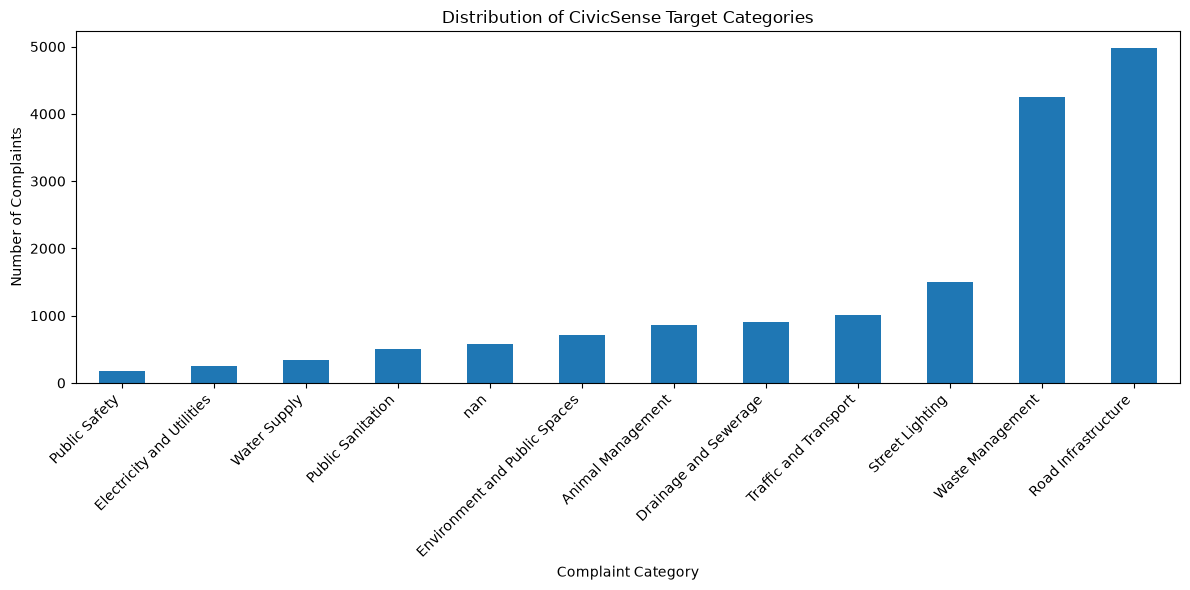

In [28]:
import matplotlib.pyplot as plt

target_distribution.dropna().sort_values().plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Distribution of CivicSense Target Categories")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
mapping_audit = (
    df.groupby(
        ["target_category", "category_title", "sub_category_title"],
        dropna=False
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["target_category", "count"],
        ascending=[True, False]
    )
)

mapping_audit.head(50)

,target_category,category_title,sub_category_title,count
7,Animal Management,Animal Husbandry,Stray Dog Sterilisation/Animal Birth Control (ABC),772
2,Animal Management,Animal Husbandry,Controlling Of Stray Pigs,33
6,Animal Management,Animal Husbandry,Removal Of Dead Animals,27
1,Animal Management,Animal Husbandry,Controlling Of Stray Cattle Or Maintenance Of Cattle Pound,16
3,Animal Management,Animal Husbandry,Dog,5
5,Animal Management,Animal Husbandry,Rabies Vaccination,4
4,Animal Management,Animal Husbandry,Maintenance Of City Meat Production And Processing Centre,2
0,Animal Management,Animal Catcher,Dog,1
11,Drainage and Sewerage,"Mobility - Roads, Footpaths and Infrastructure",Flooding/Waterlogging Of Roads And Footpaths,226
21,Drainage and Sewerage,Sewerage Systems,Maintenance And Repair Of Sewage Lines,143


### 2.6 Save a draft mapping


In [30]:
df.to_csv(
    "../data/interim/civic_complaints_mapped_draft.csv",
    index=False
)

### 2.7 Review remaining unmapped records


In [31]:
unmapped_summary = (
    unmapped.groupby(
        ["category_title", "sub_category_title"],
        dropna=False
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print(unmapped_summary.to_string(index=False))

                                           category_title                                     sub_category_title  count
                                                   Others                                                 Others    322
                    Community Infrastructure and Services                  Government Land/Property Encroachment     49
                    Community Infrastructure and Services                         Stop Unauthorised Construction     39
                                             Certificates                                           Property Tax     27
                                                   Others                                        Others - Others     24
                                                      NaN                                                    NaN     18
                    Community Infrastructure and Services                        Fencing Of BBMP/Government Land     10
                                        

In [32]:
unmapped[
    ["title", "description", "category_title", "sub_category_title"]
].sample(
    min(20, len(unmapped)),
    random_state=42
)

,title,description,category_title,sub_category_title
14237,I want my daughter birth certificate,I want my daughter birth certificate,Certificates,Birth Or Death Certificate
2091,Sewage drain fully blocked,Sewage drain fully blocked,Others,Others
4108,SEWAGE water in a plot - health hazard,SEWAGE water in a plot - health hazard,Others,Others
11345,Branches of Tree to be trimmed,Branches of Tree to be trimmed,Others,Others
15322,Voter's Id is accepted in nvsp site- But not received by POST,"Hi Voter's ID is accepted in nvsp website. But have not received by POST yet.\nWhen visited Vasanthapura BBMP office, they said it will be sent by POST. \nHow to verify this?\nNVSP reference ID: ODY658445163\nEPIC number: YER9785247",Certificates,Certificates - Other
9484,Lockdown violation during night,Site No 2 owner has conducted a party on Sunday night where men were making noise around 2:15 and 5 at night Cars were moving out during this time,Covid 19,Violation of Lockdown during Covid-19
5972,Pan shop encroached on footpath.,Pan shop encroached on footpath.,Others,Others
1056,Rude behavior of BBMP staff and he demanded money directly,"I have approached JC office, BBMP, RR nagar, Bangalore to get birth certificate for my new born baby. Staff was very rude to me, initially he shouted that hospital has not shared birth details then i called hospital and confirmed that they have sent the birth details online & shared registration number with me. When i told this to staff they accepted the application and he demanded me to give money hence i gave 50 RS then asked me to come after 1 week to collect the birth certificate. Also he told you can come some day with money if you need it urgent.",Certificates,Birth Or Death Certificate
2515,Shopkeepers taking more then MRP on milk packets here in varthur,Shopkeepers taking more then MRP on milk packets here in varthur,Others,Others
9345,Sanitary water enters rainwater drain,Sanitary water enters rainwater drain,Others,Others


### 2.8 Add further subcategory mappings


In [33]:
additional_mapping = {

    # Civic infrastructure and encroachment
    "Government Land/Property Encroachment":
        "Civic Infrastructure and Encroachment",

    "Stop Unauthorised Construction":
        "Civic Infrastructure and Encroachment",

    "Fencing Of BBMP/Government Land":
        "Civic Infrastructure and Encroachment",

    "Construction Of Residential Quarters":
        "Civic Infrastructure and Encroachment",

    "Construction Of Shopping And Commercial Complexes":
        "Civic Infrastructure and Encroachment",

    "Maintenance/Renovation Of Heritage Sites":
        "Civic Infrastructure and Encroachment",

    "Construction Of Markets":
        "Civic Infrastructure and Encroachment",

    "Construction Of Stadiums":
        "Civic Infrastructure and Encroachment",

    # Road infrastructure
    "Construction of flyovers/ underpass":
        "Road Infrastructure",

    "Construction of skywalks":
        "Road Infrastructure",

    # Environment and public spaces
    "3A- Require Playing and Gym Equipment":
        "Environment and Public Spaces",

    # Public sanitation
    "Request for Fogging/Sanitation during Covid-19":
        "Public Sanitation"
}

In [34]:
df["target_category"] = (
    df["sub_category_title"]
    .map(additional_mapping)
    .fillna(df["target_category"])
)

In [35]:
others_df = df[
    df["category_title"].eq("Others")
].copy()

In [36]:
others_df[
    ["title", "description", "sub_category_title"]
].sample(
    min(30, len(others_df)),
    random_state=42
)

,title,description,sub_category_title
4904,Maximum cab parking regularly in bus bay during school timings....,"Maximum cab parking regularly in bus bay during school timings. ka..41 .. 0940, St patrick church bus stop Museum Road.",Others
7127,School buses of SVM School larked haphazardly causing nuisance to...,School buses of SVM School larked haphazardly causing nuisance to residents.,Others
12350,Pig hunting behind residential buildings,"Wednesday, January 13, 2021: Hunters are brutally killing pigs in the backyard of residential buildings in Muthiyal Nagar which is very disturbing for people living here. Especially for kids, it's very harmful. I am sharing a video of the incident. This has to STOP.",Others
9197,Drainage pipe leaking at house #855.\n\nDespite informing the tenan...,"Drainage pipe leaking at house #855.\n\nDespite informing the tenants at house #855 on leakage of drainage pipe, they are ignoring the problem & blaming each other. Due to this the drain pipe has leaked & drain water reached other neighborhood. it has caused a strong offending stench. Also due to situation of COVID-19 there could be chances of contamination. Please resolve this issue as soon as possible.",Others
14119,No roads in layout,"The roads have been dug up and not levelled or tarred at all. Rains have made the place inaccessible . No autos/cabs want to come inside ANJANNNAPPA LAYOUT.\n Walking, driving or even looking at the road is impossible.\nI have fractured my foot while walking on these slushy roads. \nKindly pay a visit to ANJANNAPPA LAYOUT once.",Others
7347,No parking,Dear all on 28 th December we went to collect our scan report near MTR indiranagar we kept our vehicle under no parking unknowingly . But near our vehicle police vehicle has been parked BTP have taken other vehicle except police vehicle. Whether there is any rules only common public should not violate rules. In search of vehicle we need to walk 2 km in night with my daughter from MTR to indiranagar BDA.,Others
5233,Illegal extension of SR Pride Apartment gate,"The management of SR Pride Association have erected an illegal extension in the gate to prevent people from parking vehicles. This is a gate that is unused and doesnt require any obstruction. Repeated requests to the arrogant management have gone in vain. Its dangerous as kids play on the road and can hurt themselves unknowingly. If theres no street light, the extension is not visible. The apartment management has no right to encroach public property.",Others
4825,"Foothpath encroachment by mobile shop at no. 764, 50 cross, 12 ma...","Foothpath encroachment by mobile shop at no. 764, 50 cross, 12 main, 3 block rajajinagar.",Others
10018,Internet Issue,"The local internet provider has been creating a nuisance by not allowing any company to provide internet in this area. He doesn't allow any other company to provide internet in this area - airtel, act, hathway, tatasky - none of these connections are available in this area. The internet he provides is very unstable and speed is slow compared to the plan and is extremely costly as well. Now that we have work from home and use number of devices simultaneously, sometimes the speed is so slow and takes lot of time to load. We have tried to get internet connection from all the above companies, but all of them tell that they don't serve in this area. this has become really difficult. pls look into this matter with topmost priority.",Others
14472,Provided unnecessary Hump,Installed two humps on same road at different location with any reason. Requesting to remove the same.,Others


In [37]:
print(
    df["target_category"]
    .value_counts(dropna=False)
    .to_string()
)

target_category
Road Infrastructure                      4982
Waste Management                         4244
Street Lighting                          1500
Traffic and Transport                    1016
Drainage and Sewerage                     906
Animal Management                         860
Environment and Public Spaces             723
Public Sanitation                         499
NaN                                       441
Water Supply                              341
Electricity and Utilities                 256
Public Safety                             180
Civic Infrastructure and Encroachment     123


In [38]:
unmapped = df[df["target_category"].isna()]

print("Remaining unmapped:", len(unmapped))

print(
    unmapped["category_title"]
    .value_counts(dropna=False)
    .to_string()
)

Remaining unmapped: 441
category_title
Others                                                       346
Certificates                                                  53
NaN                                                           18
Community Infrastructure and Services                         10
Covid 19                                                      10
Pension                                                        1
EMP Grievance Redressal                                        1
Ration Card                                                    1
Proibition & Sale of Tobacco products, Plastic carry bags      1


In [39]:
# Export the manual-review sheet while retaining labels from an earlier run.
others_df = df[
    df["category_title"].eq("Others")
].copy()

review_path = Path("../data/interim/others_manual_review.csv")
match_cols = ["title", "description", "sub_category_title"]

if review_path.exists():
    previous_review = pd.read_csv(review_path)
    if "manual_category" in previous_review.columns:
        previous_review["manual_category"] = (
            previous_review["manual_category"]
            .replace(r"^\s*$", np.nan, regex=True)
        )
        previous_labels = previous_review.dropna(
            subset=["manual_category"]
        )
        previous_conflicts = (
            previous_labels.groupby(match_cols)["manual_category"]
            .nunique()
        )
        assert previous_conflicts.le(1).all(), (
            "Resolve conflicting labels in the existing review file first."
        )
        label_lookup = (
            previous_labels.drop_duplicates(subset=match_cols)
            .set_index(match_cols)["manual_category"]
            .to_dict()
        )
    else:
        label_lookup = {}
else:
    label_lookup = {}

others_df["manual_category"] = [
    label_lookup.get(tuple(row), "")
    for row in others_df[match_cols].itertuples(index=False, name=None)
]

others_df[
    ["title", "description", "sub_category_title", "manual_category"]
].to_csv(review_path, index=False)


In [40]:
unmapped_df = df[df["target_category"].isna()].copy()

non_others_df = unmapped_df[
    unmapped_df["category_title"] != "Others"
]

print("Remaining complaints:", len(non_others_df))

display(
    non_others_df[
        ["title", "description", "category_title", "sub_category_title"]
    ]
)

Remaining complaints: 95


,title,description,category_title,sub_category_title
2,Showing old owner name in online property tax system,"My property SAS base app no 1600800634 New Pid no 017-W0144-18-55 still showing old owner name, kindly resolve this on priority.\n\nRegards\nPradeep",Certificates,Property Tax
508,I have been roaming with the letter to enable my online payment o...,"I have been roaming with the letter to enable my online payment of tax in BBMP office, belm layout, rajarajeshwari nagar. \nThey keep telling to go from one person to another, and at the end I land up with the same person. \nor else they say come after 2 to 3 days. \njust to make the payment online I have to roam so much.. completely horrible.",Certificates,Khata Certificate
549,Wrong name of the owner of property in property tax record/application,"SAS 2016-2017 application number No. is 1601577340 and Survey number is 146/2,147/1. The owner name is still not updated to current owner i.e. me. Written application submitted with BBMP, receipt attached to this complaint. Problem still not resolved.",Certificates,Property Tax
813,Khata details not updated in online portal,I was issued khata for my apartment in year 2016-17 vide no. KTR/124/16-17.\nBut online portal of property tax payment still shows builder name. Even after complaint to local ward office. No. action taken.,Certificates,Khata Certificate
854,BBMP Bribe,Recently visited BBMP office (Bommanahalli) to transfer the name in property tax for which government staff was asking Rs 2000 as bribe. Since he asked for bribe have just submitted the form and required supporting document. Please help me to get my work done without paying bribe.,Certificates,Property Tax
...,...,...,...,...
15322,Voter's Id is accepted in nvsp site- But not received by POST,"Hi Voter's ID is accepted in nvsp website. But have not received by POST yet.\nWhen visited Vasanthapura BBMP office, they said it will be sent by POST. \nHow to verify this?\nNVSP reference ID: ODY658445163\nEPIC number: YER9785247",Certificates,Certificates - Other
15389,They work daily but they don't cover with anything and we daily a...,They work daily but they don't cover with anything and we daily are use to breathe in dust,Community Infrastructure and Services,Maintenance Of Existing Council Buildings
15536,Complaint on No Parking violation.,"I spotted a vehicle being parked in a No-Parking zone in/on 2G3Q+Q58, Satyanarayana Layout, Maruthi Nagar, Bengaluru, Karnataka 560086, India at Violation Time :undefined. Request BTP to take necessary action.",NaN,NaN
15674,Complaint on One Way becoming Two Way,"I spotted a vehicle violating one-way rule in/on XPQ5+23P, KEB Colony, Industrial Area, Hoodi, Bengaluru, Karnataka 560048 at Violation Time :undefined. Request BTP to take necessary action.",NaN,NaN


In [41]:
# Assign categories to clearly identifiable complaints
df.loc[15536, "target_category"] = "Traffic and Transport"
df.loc[15674, "target_category"] = "Traffic and Transport"

# Mark complaints outside the project's scope
exclude_indices = [2, 508, 549, 813, 854, 15322, 15754]

df.loc[exclude_indices, "target_category"] = "Exclude"

# Keep the unclear complaint for manual review
df.loc[15389, "target_category"] = np.nan

In [42]:
non_others_df[
    ["title", "description", "category_title", "sub_category_title"]
].to_csv(
    "../data/interim/non_others_manual_review.csv",
    index=True
)

## 3. Review and complete English labels


In [43]:
print("Total rows:", len(df))

print("\nTarget category distribution:")
print(df["target_category"].value_counts(dropna=False))

print("\nMissing target labels:", df["target_category"].isna().sum())

print("\nExcluded complaints:",
      (df["target_category"] == "Exclude").sum())

Total rows: 16071

Target category distribution:
target_category
Road Infrastructure                      4982
Waste Management                         4244
Street Lighting                          1500
Traffic and Transport                    1018
Drainage and Sewerage                     906
Animal Management                         860
Environment and Public Spaces             723
Public Sanitation                         499
NaN                                       432
Water Supply                              341
Electricity and Utilities                 256
Public Safety                             180
Civic Infrastructure and Encroachment     123
Exclude                                     7
Name: count, dtype: int64

Missing target labels: 432

Excluded complaints: 7


In [44]:
remaining_df = df[df["target_category"].isna()].copy()

print("Remaining unmapped complaints:", len(remaining_df))

print("\nOriginal category distribution:")
print(remaining_df["category_title"].value_counts(dropna=False))

print("\nSubcategory distribution:")
print(remaining_df["sub_category_title"].value_counts(dropna=False).head(30))

Remaining unmapped complaints: 432

Original category distribution:
category_title
Others                                                       346
Certificates                                                  46
NaN                                                           16
Community Infrastructure and Services                         10
Covid 19                                                      10
Pension                                                        1
EMP Grievance Redressal                                        1
Ration Card                                                    1
Proibition & Sale of Tobacco products, Plastic carry bags      1
Name: count, dtype: int64

Subcategory distribution:
sub_category_title
Others                                                    323
Property Tax                                               24
Others - Others                                            24
NaN                                                        16
Violation of

In [45]:
display(
    remaining_df[
        ["title", "description", "category_title", "sub_category_title"]
    ]
)

,title,description,category_title,sub_category_title
1,Money menace is a huge problem with residents of Chikka Banaswadi...,Money menace is a huge problem with residents of Chikka Banaswadi.\nMonkeys come in groups and create lot of problem. Please assign this to right authority to get it rectified,Others,Others
29,No Road and Sanitation,"No roads yet, despite of multiple complaints. No sanitary connections yet, have been asking to provide this facility on priority as there are no options for a resident of this layout.",Others,Others
71,Qnet fraud scam spearheading again,"Qnet frauds calling and brainwashing housewives in the name of additional income and asking to invest 3 to 10 lakhs in MLM business \n\nThey all meet in cafe coffee day in indira nagar opposite to icici bank \n\nBefore people get cheated., they should be stopped",Others,Others
118,Unauthorised commercial establishments causing lots of inconvenie...,Unauthorised commercial establishments causing lots of inconvenience to neighborhood and pedestrians blocking their footpaths putting them to danger.,Others,Others
219,This is in regards to the BWSSB bore connection ... A person name...,This is in regards to the BWSSB bore connection ... A person named Umesh without any ID Card comes and ask for money for supplying bore water when we've have already paid in the monthly bill ... plz look into the matter soon.,Others,Others
...,...,...,...,...
15913,Rejection of Voters ID,"Application nos. OAR367057741, OQT357436426,OPH496656065,ONP978565645 is been rejected without verification. All document submitted with Aadhar card, address proof, age proof electricity bill, gas bill. \nReason mentioned is wrong address but we are staying in this address from October 2020.",Others,Others
15943,Without concerned Authority permission selling old fish on sunday...,Without concerned Authority permission selling old fish on sundays and place of hygiene is pathetic which may cause severe public health issue by consumption of fish... \nso kindly take action.,Others,Others
15966,Right in the middle of road - can this be levelled so that two wh...,Right in the middle of road - can this be levelled so that two wheelers drive safely,Others,Others
15973,Road not levelled even after 10 months after BESCOM work,Road not levelled even after 10 months after BESCOM work,Others,Others


In [46]:
# Load the completed manual review
review_df = pd.read_csv(
    "../data/interim/others_manual_review.csv"
)

# Columns used to match complaints
match_cols = ["title", "description", "sub_category_title"]

# Check that identical complaints do not have conflicting labels
conflicts = (
    review_df.groupby(match_cols)["manual_category"]
    .nunique()
)

assert conflicts.le(1).all(), "Some complaints have conflicting manual labels."

# Create a lookup dictionary
review_lookup = (
    review_df.drop_duplicates(subset=match_cols)
    .set_index(match_cols)["manual_category"]
    .to_dict()
)

# Apply the manual decisions to the original Others complaints
mask = df["category_title"].eq("Others")

df.loc[mask, "target_category"] = [
    review_lookup.get(tuple(row), np.nan)
    for row in df.loc[mask, match_cols].itertuples(index=False, name=None)
]

print("Updated Others complaints:", mask.sum())
print("\nUpdated target distribution:")
print(df["target_category"].value_counts(dropna=False))

Updated Others complaints: 346

Updated target distribution:
target_category
Road Infrastructure                      5035
Waste Management                         4252
Street Lighting                          1503
Traffic and Transport                    1070
Drainage and Sewerage                     929
Animal Management                         885
Environment and Public Spaces             741
Public Sanitation                         505
Water Supply                              351
Electricity and Utilities                 261
Public Safety                             196
Civic Infrastructure and Encroachment     169
Exclude                                    88
NaN                                        86
Name: count, dtype: int64


In [47]:
remaining_df = df[df["target_category"].isna()].copy()

print("Remaining unmapped:", len(remaining_df))

print("\nOriginal category distribution:")
print(remaining_df["category_title"].value_counts(dropna=False))

Remaining unmapped: 86

Original category distribution:
category_title
Certificates                                                 46
NaN                                                          16
Community Infrastructure and Services                        10
Covid 19                                                     10
Pension                                                       1
EMP Grievance Redressal                                       1
Ration Card                                                   1
Proibition & Sale of Tobacco products, Plastic carry bags     1
Name: count, dtype: int64


### 3.1 Resolve remaining unmapped complaints


### 3.2 Mark clearly out-of-scope complaints


In [48]:
exclude_categories = [
    "Certificates",
    "Covid 19",
    "Pension",
    "EMP Grievance Redressal",
    "Ration Card"
]

df.loc[
    df["category_title"].isin(exclude_categories) &
    df["target_category"].isna(),
    "target_category"
] = "Exclude"

### 3.3 Apply the final manual review


In [49]:
review_remaining = df[df["target_category"].isna()].copy()

display(
    review_remaining[
        [
            "title",
            "description",
            "category_title",
            "sub_category_title"
        ]
    ]
)

,title,description,category_title,sub_category_title
6535,Anganwadi -Teacher,"In Yarab Nagar Anganwadi opposite to Ambedkar statue ,from last 3 months there is no teacher to teach children only helper is there and children's are going there and coming back to home because of this problem.\n\nI went to children welfare office to ask about this vacancy but they told that there is no any update for them.\nKindly have a look this is problem. Hope you will definitely take action against this complaint.\n\nthanks,\nSalma Babu",Community Infrastructure and Services,Maintenance Of Educational Institutions And Libraries
7210,Library open panarathu elliy sir,2 year no open library my village students reading Pana mutila,Community Infrastructure and Services,Maintenance Of Educational Institutions And Libraries
9694,Maintenance,"Respected Sir/Madam,\nIt's a big nuisance since it's in the residential area. Kindly lift it completely so that it won't be a disturbance to the people of this area. We are facing lot of problems, like there are lot of snakes, which is multiplying in number. Kindly look into the matter and kindly do the needful. \nThanking you ??",Community Infrastructure and Services,Maintenance Of Crematoriums And Burial ground
9927,Burial ground behind Westend heights club house,"Sir,\nPeople are burying dead bodies every third day behind the club house\nThere is no office anything there, who knows what kind of illegal burying is happening there.Just now around 9 pm they came and buried in darkness.\nSir, please stop these activities in the middle of resedential colony.they can be covid also.\nPlease don't allow dead bodies to be buried in the middle of resedential area.\nKindly do the needful at the earliest.",Community Infrastructure and Services,Construction Of Crematoriums And Burial ground
10013,Rahul store,They charge above mrp for milk and curd products...for 10 rs milk they charge curd,Community Infrastructure and Services,Maintenance Of Shopping And Commercial Complexes
10332,On the west of chord road near first block a guy in i rickshaw sp...,On the west of chord road near first block a guy in i rickshaw spat on the road without any concern of the COVID 19 spread. He also went ahed to ignore us while we were talking to him. Utterly disrespectful his rickshaw number was - KA 53C 7332. Please take actions as soon as possible,"Proibition & Sale of Tobacco products, Plastic carry bags",Spitting
10541,Shantinagar Post Office is in extremely poor condition. It is a b...,"Shantinagar Post Office is in extremely poor condition. It is a black spot parading as a service t community. completely neglected and left in dilapidated condition. pls pull up the local corporaters who should look into the below basic necessities-\nCCTV?? Guard?? (it is also serving as a bank with depositors queuing up with cash), parking??, drinking water?? sitting area??, 1 lady staffer only, poor lighiting and ventilation. when was it last painted?? no place to form a queue inside. it is a disgrace that tax payers money is not used effectively on basic community services like the local post office",Community Infrastructure and Services,Maintenance Of Existing Ward & Zonal Offices
11211,Complaint About Stray Dogs Issues,report a stray dog,NaN,NaN
11311,Complaint on No Parking violation.,"I spotted a vehicle being parked in a No-Parking zone in/on 1362/1, 31st Cross Rd, 4th T Block East, Jayanagar, Bengaluru, Karnataka 560041, India at Violation Time :undefined. Request BTP to take necessary action.",NaN,NaN
12453,Complaint on No Parking violation.,"I spotted a vehicle being parked in a No-Parking zone in/on Ramanjaneyanagar, Chikkalasandra, Bengaluru, Karnataka 560061 at Violation Time :undefined. Request BTP to take necessary action.",NaN,NaN


In [50]:
review_remaining[
    [
        "title",
        "description",
        "category_title",
        "sub_category_title"
    ]
].to_csv(
    "../data/interim/final_27_manual_review.csv",
    index=True
)

In [51]:
manual_mapping = {
    # Civic Infrastructure and Encroachment
    7210: "Civic Infrastructure and Encroachment",
    9694: "Civic Infrastructure and Encroachment",
    9927: "Civic Infrastructure and Encroachment",
    10541: "Civic Infrastructure and Encroachment",
    13632: "Civic Infrastructure and Encroachment",
    14049: "Civic Infrastructure and Encroachment",
    14260: "Civic Infrastructure and Encroachment",

    # Public Sanitation
    10332: "Public Sanitation",

    # Animal Management
    11211: "Animal Management",

    # Traffic and Transport
    11311: "Traffic and Transport",
    12453: "Traffic and Transport",
    12520: "Traffic and Transport",
    12629: "Traffic and Transport",
    12942: "Traffic and Transport",
    12971: "Traffic and Transport",
    13081: "Traffic and Transport",
    13101: "Traffic and Transport",
    13317: "Traffic and Transport",
    13354: "Traffic and Transport",
    13635: "Traffic and Transport",
    13647: "Traffic and Transport",
    13978: "Traffic and Transport",
    13996: "Traffic and Transport",
    15233: "Traffic and Transport",

    # Environment and Public Spaces
    15389: "Environment and Public Spaces"
}

# Apply manual classifications
for idx, category in manual_mapping.items():
    df.loc[idx, "target_category"] = category

# Exclude complaints outside the project scope
df.loc[[6535, 10013], "target_category"] = "Exclude"

In [52]:
print("Total rows:", len(df))

print("\nRemaining unmapped:",
      df["target_category"].isna().sum())

print("\nExcluded complaints:",
      (df["target_category"] == "Exclude").sum())

print("\nFinal category distribution:")
print(df["target_category"].value_counts(dropna=False))

Total rows: 16071

Remaining unmapped: 0

Excluded complaints: 149

Final category distribution:
target_category
Road Infrastructure                      5035
Waste Management                         4252
Street Lighting                          1503
Traffic and Transport                    1085
Drainage and Sewerage                     929
Animal Management                         886
Environment and Public Spaces             742
Public Sanitation                         506
Water Supply                              351
Electricity and Utilities                 261
Public Safety                             196
Civic Infrastructure and Encroachment     176
Exclude                                   149
Name: count, dtype: int64


## 4. Finalize the English labelled dataset


### 4.1 Remove excluded records and inspect duplicates


In [53]:
# Keep only the 12 valid categories
final_df = df[
    df["target_category"].notna() &
    (df["target_category"] != "Exclude")
].copy()

print("Dataset before duplicate removal:", final_df.shape)

# Identify exact duplicate records
duplicates = final_df[
    final_df.duplicated(keep=False)
].sort_values(by="title")

print("Exact duplicate rows:", final_df.duplicated().sum())

display(duplicates[
    ["title", "description", "target_category"]
].head(20))

Dataset before duplicate removal: (15922, 18)


Exact duplicate rows: 33


,title,description,target_category
5845,Abandoned vehicle parked since 15 days,Abandoned vehicle parked since 15 days,Traffic and Transport
5846,Abandoned vehicle parked since 15 days,Abandoned vehicle parked since 15 days,Traffic and Transport
7796,Damage road,Road digging happened for water work.. Still not done proper road work after that..,Road Infrastructure
7797,Damage road,Road digging happened for water work.. Still not done proper road work after that..,Road Infrastructure
6502,Garbage bins,Can you please install garbage bins anywhere on hosa road soo that people can dump waste instead of throwing it by the side of road. Not everyone are available when bbmp people come to collect waste because of people having different job shifts.its a request please take it serious and take some quick action,Waste Management
6503,Garbage bins,Can you please install garbage bins anywhere on hosa road soo that people can dump waste instead of throwing it by the side of road. Not everyone are available when bbmp people come to collect waste because of people having different job shifts.its a request please take it serious and take some quick action,Waste Management
5275,Garbage disposed in front of kumbara sangha hostel building pleas...,Garbage disposed in front of kumbara sangha hostel building please take necessary steps to clear this garbage this is routine here 3 to 4 days it will be like this only later somebody will put fire on this... Please take effective action,Waste Management
5276,Garbage disposed in front of kumbara sangha hostel building pleas...,Garbage disposed in front of kumbara sangha hostel building please take necessary steps to clear this garbage this is routine here 3 to 4 days it will be like this only later somebody will put fire on this... Please take effective action,Waste Management
6364,Garbage dump on Chunchunkatta Main Road near Kiran Medical. This...,Garbage dump on Chunchunkatta Main Road near Kiran Medical. This garbage dump is hazardous to stray cows. Please remove this garbage.,Waste Management
6365,Garbage dump on Chunchunkatta Main Road near Kiran Medical. This...,Garbage dump on Chunchunkatta Main Road near Kiran Medical. This garbage dump is hazardous to stray cows. Please remove this garbage.,Waste Management


### 4.2 Save the labelled dataset


In [54]:
final_df = final_df.drop_duplicates().copy()

print("Final dataset shape:", final_df.shape)
print("Unique categories:", final_df["target_category"].nunique())

print("\nFinal category distribution:")
print(final_df["target_category"].value_counts())

Final dataset shape: (15889, 18)
Unique categories: 12

Final category distribution:
target_category
Road Infrastructure                      5027
Waste Management                         4237
Street Lighting                          1501
Traffic and Transport                    1083
Drainage and Sewerage                     924
Animal Management                         886
Environment and Public Spaces             742
Public Sanitation                         505
Water Supply                              351
Electricity and Utilities                 261
Public Safety                             196
Civic Infrastructure and Encroachment     176
Name: count, dtype: int64


In [55]:
final_df.to_csv(
    "../data/interim/civic_complaints_labelled.csv",
    index=False
)

## 5. Inspect language distribution in the English dataset


In [56]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

In [57]:
final_df["text"] = (
    final_df["title"].fillna("") + " " +
    final_df["description"].fillna("")
).str.strip()

In [58]:
def detect_language(text):
    try:
        return detect(text)
    except:
        return "unknown"

final_df["detected_language"] = final_df["text"].apply(
    detect_language
)

print(final_df["detected_language"].value_counts())

detected_language
en         15270
af           165
id            78
tl            55
da            47
nl            42
de            34
unknown       32
fr            29
no            18
so            18
et            18
sv            10
it             9
vi             8
cy             7
ro             7
ca             7
es             6
sw             6
pt             5
sl             3
hr             3
hu             2
sq             2
cs             2
fi             2
lv             1
sk             1
tr             1
lt             1
Name: count, dtype: int64


In [59]:
import re

def contains_devanagari(text):
    return bool(re.search(r"[\u0900-\u097F]", text))

final_df["contains_devanagari"] = final_df["text"].apply(
    contains_devanagari
)

print(final_df["contains_devanagari"].value_counts())

contains_devanagari
False    15889
Name: count, dtype: int64


In [60]:
hinglish_sample = final_df.sample(
    n=100,
    random_state=42
)

display(
    hinglish_sample[
        ["title", "description", "target_category"]
    ]
)

,title,description,target_category
10345,Removal of Stray Pigs,"Dear Authority,\n\nWith humble request, I would request to remove a bunch of stray pigs creating menace in the neighborhood. Whole night and day they keep making mess on the road, create loud noises, fight within. This gets really disturbing in night. They have reproduced multiple folds in the last year. \n\nPlease help us.",Animal Management
13854,Road is not motorable since last 2 years,"Road leading to MLA layout from Bannerghatta road was dug up several times for lying cables, sewage work etc.. Immediately after the road construction was over and opened-up for public. Dug up road never repaired after this . \nMore than 1000's of people staying in this Layout is suffering due to the bad road condition especially during rain its not even walkable for pedestrians.\nThis stretch is hardly 500 to 700 meter length. even auto rickshaws unwilling to enter here on rainy days due to potholes and pathetic road condition.",Road Infrastructure
10877,Pot hole damaged and covered with trees in the middle of road cau...,"Pot hole damaged and covered with trees in the middle of road causing discomfort and chances of accidents. Near Raghavendra Matt, Akshaya Nagar, Off Bannerghatta Road, Bangalore - 560068",Road Infrastructure
12263,Debris on footpath near Ganesh Temple,Debris on footpath near Ganesh Temple,Waste Management
5183,The road on the opposite side of Kalyani motors on Bannerghatta r...,The road on the opposite side of Kalyani motors on Bannerghatta road is very horrible shape. one side of road is fixed to few meters. please reapair other side of the road and save our life's please,Road Infrastructure
...,...,...,...
8954,Street light switches off as soon as it turns off,The light switches off seconds after it turns on,Street Lighting
14586,Garbage issue,Garbage issue,Waste Management
2774,Bad road,Road condition is pathetic starting from Mayura bakery Whitefield till Sri Rama temple immadihalli road Whitefield,Road Infrastructure
3453,Polluting water resource by dumping debris,"By constant dumping of debris, water resource gets polluted and depleted.\nNearby residents get affected by dengue.",Waste Management


## 6. Audit the multilingual complaint dataset


### 6.1 Load the multilingual data


In [61]:
MULTI_DATA_PATH = Path(
    "../data/external/civic_complaints_dataset.csv"
)

multi_df = pd.read_csv(MULTI_DATA_PATH)

print("Dataset shape:", multi_df.shape)

display(multi_df.head())

Dataset shape: (29137, 12)


,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse
0,"Classify this complaint: ""Sir, we are facing lot of water problem in 8th main byrappa layout s g palya, c v Raman Nagar Bangalore 93.\nI have mailed to Mr.Raghu regarding this!! But no response we have approached the bjp office in the area but no response!\nSome1 called Seena in the area is put in charge of supplying water to """,Water Leakage,"Sir, we are facing lot of water problem in 8th main byrappa layout s g palya, c v Raman Nagar Bangalore 93.\nI have mailed to Mr.Raghu regarding this!! But no response we have approached the bjp office",Opp to seed of truth church,HIGH,Water Supply,high,English,0.9,frustrated,[],Your complaint has been registered with the Water Supply department as HIGH priority.
1,"Classify this complaint: ""Doddabommasandra Arch se Nanjappa Circle, Nanjappa Circle se Vidyaranyapura First block tak behtar paidal margon ki avashyakta hai, jo is samay uplabdh nahin hain.""",Garbage Overflow,"Doddabommasandra Arch se Nanjappa Circle, Nanjappa Circle se Vidyaranyapura First block tak behtar paidal margon ki avashyakta hai, jo is samay uplabdh nahin hain.",Location not specified,MEDIUM,Sanitation,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Sanitation department as MEDIUM priority.
2,"Classify this complaint: ""Kachra kachra kachra""",Garbage Overflow,Kachra kachra kachra,Sainik Public School Road Dead end 6th Cross Vidhanasoudha Layout,MEDIUM,Sanitation,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Sanitation department as MEDIUM priority.
3,"Classify this complaint: ""Garbage dumped next to mysore circle bus stop. It is very difficult for passengers to stand or sit in bus stop awaiting for bus.""",Garbage Overflow,Garbage dumped next to mysore circle bus stop. It is very difficult for passengers to stand or sit in bus stop awaiting for bus.,Mysore circle bus stop way to KR Market,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
4,"Classify this complaint: ""Too many pot holes near GIIS school and petrol bunk-Gunjur\nFill it as early as possible""",Pothole,Too many pot holes near GIIS school and petrol bunk-Gunjur\nFill it as early as possible,Near Petrol bunk,HIGH,Road Maintenance,high,English,0.9,frustrated,[],Your complaint has been registered with the Road Maintenance department as HIGH priority.


### 6.2 Inspect its structure and completeness


In [62]:
print("Columns:")
print(multi_df.columns.tolist())

print("\nDataset information:")
multi_df.info()

print("\nMissing values:")
print(multi_df.isnull().sum())

Columns:
['instruction', 'issueType', 'description', 'location', 'priority', 'department', 'urgency', 'detectedLanguage', 'aiConfidence', 'sentiment', 'keywords', 'suggestedResponse']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 29137 entries, 0 to 29136
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   instruction        29137 non-null  str    
 1   issueType          29137 non-null  str    
 2   description        29137 non-null  str    
 3   location           29137 non-null  str    
 4   priority           29137 non-null  str    
 5   department         29137 non-null  str    
 6   urgency            29137 non-null  str    
 7   detectedLanguage   29137 non-null  str    
 8   aiConfidence       29137 non-null  float64
 9   sentiment          29137 non-null  str    
 10  keywords           29137 non-null  str    
 11  suggestedResponse  29137 non-null  str    
dtypes: float64(1), str(

### 6.3 Examine language and label distributions


In [63]:
print("Language distribution:")
print(multi_df["detectedLanguage"].value_counts())

print("\nIssue type distribution:")
print(multi_df["issueType"].value_counts())

print("\nPriority distribution:")
print(multi_df["priority"].value_counts())

print("\nDepartment distribution:")
print(multi_df["department"].value_counts())

Language distribution:
detectedLanguage
English     9921
Hinglish    9608
Hindi       9608
Name: count, dtype: int64

Issue type distribution:
issueType
Garbage Overflow          11105
Damaged Infrastructure     8786
Pothole                    4705
Broken Streetlight         3688
Water Leakage               853
Name: count, dtype: int64

Priority distribution:
priority
HIGH        13189
MEDIUM      11608
CRITICAL     3203
LOW          1137
Name: count, dtype: int64

Department distribution:
department
Road Maintenance          11924
Sanitation                11105
Electrical Department      3688
General Administration     1567
Water Supply                853
Name: count, dtype: int64


### 6.4 Check duplicate and conflicting labels


In [64]:
print("Exact duplicate rows:", multi_df.duplicated().sum())

print(
    "Repeated descriptions:",
    multi_df.duplicated(subset=["description"]).sum()
)

description_groups = multi_df.groupby("description").agg(
    complaint_count=("description", "size"),
    issue_types=("issueType", "nunique"),
    priorities=("priority", "nunique")
)

conflicting_labels = description_groups[
    (description_groups["complaint_count"] > 1) &
    (
        (description_groups["issue_types"] > 1) |
        (description_groups["priorities"] > 1)
    )
]

print(
    "Descriptions with conflicting labels:",
    len(conflicting_labels)
)

Exact duplicate rows: 659
Repeated descriptions: 974
Descriptions with conflicting labels: 79


### 6.5 Compare labels across languages


In [65]:
language_issue_table = pd.crosstab(
    multi_df["issueType"],
    multi_df["detectedLanguage"]
)

display(language_issue_table)

detectedLanguage,English,Hindi,Hinglish
issueType,,,
Broken Streetlight,1248,1220,1220
Damaged Infrastructure,3004,2891,2891
Garbage Overflow,3775,3665,3665
Pothole,1601,1552,1552
Water Leakage,293,280,280


In [66]:
priority_language_table = pd.crosstab(
    multi_df["detectedLanguage"],
    multi_df["priority"]
)

display(priority_language_table)

priority,CRITICAL,HIGH,LOW,MEDIUM
detectedLanguage,,,,
English,1097,4479,391,3954
Hindi,1053,4355,373,3827
Hinglish,1053,4355,373,3827


In [67]:
department_issue_table = pd.crosstab(
    multi_df["issueType"],
    multi_df["department"]
)

display(department_issue_table)

department,Electrical Department,General Administration,Road Maintenance,Sanitation,Water Supply
issueType,,,,,
Broken Streetlight,3688,0,0,0,0
Damaged Infrastructure,0,1567,7219,0,0
Garbage Overflow,0,0,0,11105,0
Pothole,0,0,4705,0,0
Water Leakage,0,0,0,0,853


In [68]:
multi_df.groupby(
    ["detectedLanguage", "issueType"]
).size().unstack(fill_value=0)

issueType,Broken Streetlight,Damaged Infrastructure,Garbage Overflow,Pothole,Water Leakage
detectedLanguage,,,,,
English,1248,3004,3775,1601,293
Hindi,1220,2891,3665,1552,280
Hinglish,1220,2891,3665,1552,280


In [69]:
for language in ["English", "Hindi", "Hinglish"]:
    print(f"\n--- {language} examples ---")

    display(
        multi_df[
            multi_df["detectedLanguage"] == language
        ][["description", "issueType", "priority"]].sample(
            5, random_state=42
        )
    )


--- English examples ---


,description,issueType,priority
15550,"Hi , AECS A block has sever water problems , i would like to know when would we receive Kaveri connections for AECS A block.",Water Leakage,HIGH
1487,Building Debris,Garbage Overflow,HIGH
12737,Half of the road is occupied by people house which is under construction and causing inconveniences while passing through,Damaged Infrastructure,MEDIUM
24772,Transformer giving out sparks at regular intervals,Broken Streetlight,MEDIUM
26610,Begur main road after chowdaeshwari temple petrol bank road connective is bad.. due to cauvery water connection pipeline work road is diggied completely and making difficult to communicate to travel.,Damaged Infrastructure,MEDIUM



--- Hindi examples ---


,description,issueType,priority
6508,"विजयनगर मेट्रो स्टेशन के पास, बड़ी मात्रा में कचरा जमा हो गया है। कृपया जल्द से जल्द उचित कार्रवाई करें। धन्यवाद। सादर, अशोक टी एस",Garbage Overflow,HIGH
15605,सबसे खराब सड़क और पूरी तरह से गड्ढों से भरी हुई है। कृपया बीबीएमपी जाग जाओ।,Damaged Infrastructure,MEDIUM
24718,इस सड़क पर सीवेज का कुछ काम चल रहा था। ऐसा करने के लिए सब कुछ खोदा गया था। अब सड़क पूरी तरह से टूट गई है और सड़क पर कीचड़ ही कीचड़ है।\n\nजब बारिश होती है तो सड़क पूरी तरह से कीचड़ भरी हो जाती है। बिना,Damaged Infrastructure,HIGH
8837,पिछले महीने बी बी एम पी के कर्मचारी एक ड्रेनेज लाइन ठीक करने आए थे और उन्होंने पूरी सड़क तोड़ दी थी और तब से यह अधूरी है।,Pothole,HIGH
24198,"80 फीट रोड, एलबीएस नगर, अंजनापुरा बीडीए लेआउट\n\nमेरी पिछली शिकायत/अनुरोध पर कार्रवाई करने के लिए टीम को धन्यवाद। गोटीगेरे में सड़कें अब मरम्मत के अधीन हैं।\n\nइसी तरह की स्थिति एलबीएस नगर, अंजनापुरा में",Damaged Infrastructure,MEDIUM



--- Hinglish examples ---


,description,issueType,priority
6312,"Street lights kaam nahi kar rahi hain. 1st Cross, Royal County Layout, Parappana Agrahara. Isse raat mein residents ko serious inconvenience ho rahi hai.",Broken Streetlight,CRITICAL
15281,"Bellandur mein, Ecospace Tech Park ke paas, ek bahut bada gaddha hai aur paani jama ho gaya hai. Jama hua paani har vehicle par chhalak raha hai... Yeh 2 saptah se adhik samay se hai... BBMP aisi chee",Damaged Infrastructure,HIGH
24576,Street light kaam nahi kar rahi hai,Broken Streetlight,MEDIUM
8596,Bangalore mein barish hui hai yeh kaise pata karein? Bijli cutti se jo bina kisi karan ke ghanto tak chalti hai!,Broken Streetlight,MEDIUM
24109,"Shanti Layout, Mallasandra ward no. 13, Jalahalli West, Bengaluru - 560015 mein gehra gaddha hai. Yeh BWSSB sewage line ke theek upar hai aur agar ise turant theek nahi kiya gaya toh yeh gehra ho sakt",Pothole,CRITICAL


## 7. Validate multilingual issue labels


In [70]:
damaged_df = multi_df[
    multi_df["issueType"] == "Damaged Infrastructure"
].copy()

print("Total complaints:", len(damaged_df))

for language in ["English", "Hindi", "Hinglish"]:

    print(f"\n========== {language} ==========")

    sample = damaged_df[
        damaged_df["detectedLanguage"] == language
    ].sample(n=10, random_state=42)

    display(
        sample[
            ["description", "priority", "department"]
        ]
    )

Total complaints: 8786

========== English ==========


,description,priority,department
7324,"Sir, can you please remove the water pipe from 13th Cross 3rd block. which is causing accidents.",CRITICAL,Road Maintenance
23536,"Hi,\n\nThe charles campbell road and ramakrishnappa road are in pathetic state for years now. Absolutely neglected to the point that now they have become dangerous to drive. Could you please do some lon",CRITICAL,Road Maintenance
1681,"Road in Pathetic condition @ Sowrastrapet Main Road, ward no.109. BWSSB had dug up road 3 months back to lay sewage pipeline and have left unrepaired. The road has become MUD ROAD, please see the ph",MEDIUM,Road Maintenance
548,Driving k. footpath,MEDIUM,Road Maintenance
5697,"Vehicle no : KA 41 W 7130\nViolation : Triple riding + no helmets for all.\nLocation : Gublala , opposite to Pride Appartment.560061.\nDate : 9 Feb 2022 . 10 AM.",LOW,General Administration
27519,The Side road has been cut off since 2 months for constructing road drains. We have been co operating with construction people and managing to somehow cross the drains without support. Now that the dr,HIGH,Road Maintenance
18944,The roads surrounding the park and on the location mentioned above are really worst. Recently some drainage work was done and it was not cleaned properly resulting in full mud and dust. Please conside,MEDIUM,Road Maintenance
6671,Yesterday evening as I was walkimg home from work a man came riding his bike on the pavement behind me a high speed and honking. He tried to push past me when I asked him to get off the pavement and w,MEDIUM,Road Maintenance
24336,"Situation on Cambridge Main Road is at CRITICAL level of pollution due to dust from road work done recently. Photos are of dust accumulated in just 1 day. Residents of Cambridge Rd, Udani Layout are f",MEDIUM,Road Maintenance
1950,"Roads are very bad can't walk also .cant drive cars in this dirty roads, from last 5 years so many accidents in this village road.. Location is Kaggalipura village, huskur post, Anekal taluk Bangalore",CRITICAL,Road Maintenance



========== Hindi ==========


,description,priority,department
4909,"उत्तराहल्ली वार्ड के एक निवासी ने सिम्हाद्री लेआउट में मेरे घर के सामने निर्माण का मलबा डाल दिया है। कई बार हटाने का अनुरोध करने के बाद, वे हमें धमकी देते हैं और बहुत घटिया तरीके से चिल्लाते हैं। मैंन",CRITICAL,Road Maintenance
12166,क 02 पी 6244,MEDIUM,Road Maintenance
23831,"पिछले हफ्ते इस साझा स्थान पर कुछ लोग केबल डालने के लिए पूरी सड़क खोद रहे थे, जिसके बाद से यह पूरी सड़क अच्छी स्थिति में नहीं है। कृपया किसी के घायल होने से पहले इसे डामर से ठीक करवाएं।\nमैंने एक नमूने",HIGH,Road Maintenance
20989,"हमारे अपार्टमेंट, शेल नॉर्थगेट के सामने की कच्ची सड़क बहुत खराब हालत में है। हम आपसे अनुरोध करते हैं कि हमारी सड़क को पक्का कर दें।",MEDIUM,Road Maintenance
29119,"आप लोग वास्तव में बहुत बढ़िया हैं, आपका निर्माण और रखरखाव इतना शानदार है कि इसे हर हफ्ते रखरखाव की आवश्यकता होती है। सार्वजनिक जगहों पर हर हफ्ते खुदाई और नालियों की सफाई की जाती है, जिससे लोगों को चलन",HIGH,Road Maintenance
12884,यहां सड़क कभी नहीं बनी। हम एक मेट्रो शहर के लिए किराया/जमा दे रहे हैं और सड़कें गांव की कच्ची सड़क से भी बदतर हैं। बेहतर होगा यदि इस क्षेत्र में सड़कों का निर्माण किया जाए।,MEDIUM,Road Maintenance
24877,फुटपाथ पर कार,LOW,General Administration
23291,"मेरे घर के पास की सड़क को पाइपलाइन बिछाने के लिए खोदा गया था, लेकिन उसे महीनों से ऐसे ही छोड़ दिया गया है। इस वजह से बहुत धूल और दुर्घटनाएँ हो रही हैं, और हमें दमा भी हो रहा है। कृपया कुछ करें।",CRITICAL,Road Maintenance
10873,"कल्कere मेन रोड का पूरा खंड, जयंती नगर सर्कल से लेकर कल्कere HP पेट्रोल पंप तक पूरी तरह से खुदा हुआ है, और इतना खतरनाक और दयनीय स्थिति में है कि लोग यात्रा करने में असमर्थ हैं, भारी धूल से भरा हुआ है,",CRITICAL,Road Maintenance
12873,"यह सड़क राममूर्ति नगर के निवासियों के लिए कस्तूरी नगर फ्लाईओवर को बायपास करने का एक लिंक है और यह सड़क के.आर. पुरम ट्रैफिक पर तनाव को कम करती है।\n\nहालांकि, सड़क के दोनों किनारों पर भारी ट्रक और अन्य व",MEDIUM,Road Maintenance



========== Hinglish ==========


,description,priority,department
4978,"Hebbal signal par BEL circle se aane wale traffic ko, Nagawara ki or seedhe jaane ya airport ki or baayein mudne ke liye, keval 500 meter paar karne mein 15-20 minute lagte hain. Is asahniya traffic k",MEDIUM,Road Maintenance
11952,"Humare layout Krishna Block 1, RR Nagar ward mein pichle 3 saalon se road nahi hai, humne kai shikayatein ki hain lekin kuch nahi hua, BBMP ko turant karwai karne ki zaroorat hai.",MEDIUM,Road Maintenance
23492,"Hello Sir,\n\nJo roads Hennur Ring Road se Kothanur tak aur Narwara se Hegde Nagar tak jaati hain, wo puri tarah se kharab hain.\n\nYeh situation pichle kuch mahino se bani hui hai.\n\nMujhe pata hai ki yeh",MEDIUM,Road Maintenance
20549,Paani bhar gaya hai aur baarish mein yahan travel karna bahut mushkil hai.,MEDIUM,Road Maintenance
29057,"Sadak ko beech se paani ki pipeline ke liye khoda gaya hai lekin nayi sadak nahi banayi gayi hai, kripya samadhan karein.",MEDIUM,Road Maintenance
12672,"Mai Shriram Sameeksha, Jalahalli, Abbigere ka nivasi hun. Builder dwara sabhi nivasiyon ko apartment saupe hue 3 saal se adhik ho gaye hain, lekin Sameeksha ke saamne wali sadak par abhi tak tarkol na",MEDIUM,Road Maintenance
24553,"Priye Mahoday/Mahodaya,\n Mera naam Shabnam.M hai, mai #36, 2nd main, 2nd cross, Papanna Layout, Bharat Nagar, Saraipalya, Thanisandra Main Road, SRK Post, Bangalore 560077 mein rehti hoon. Shrimaan",MEDIUM,Road Maintenance
22802,"Sabhi footpathon par vikretaon ka atikraman hai. Jo shahar footpath par bechne ki anumati dete hain, ve aam taur par footpath ke 1/3 bhaag tak istemal karne ki anumati dete hain. Bangalore mein vikret",CRITICAL,Road Maintenance
10612,"Mukhya sadak se pravesh marg avaruddh hai. Auto, logon ka yatayat aur awara kutte adhik hain. Aas-paas ki dukano aur bahar aane-jaane wale pariwaro ko samasya ho rahi hai. Kripya iska samadhan nikale.",MEDIUM,Road Maintenance
12615,Neelkant Jewellers Richmond Road Bangalore 560025 ke bahar street light kharab hai.,HIGH,Road Maintenance


### 7.1 Inspect all available issue types

In [71]:
print("Available issue types:")
print(multi_df["issueType"].value_counts())

print("\nAvailable languages:")
print(multi_df["detectedLanguage"].value_counts())

print("\nIssue type and language combinations:")

display(
    pd.crosstab(
        multi_df["issueType"],
        multi_df["detectedLanguage"]
    )
)

Available issue types:
issueType
Garbage Overflow          11105
Damaged Infrastructure     8786
Pothole                    4705
Broken Streetlight         3688
Water Leakage               853
Name: count, dtype: int64

Available languages:
detectedLanguage
English     9921
Hinglish    9608
Hindi       9608
Name: count, dtype: int64

Issue type and language combinations:


detectedLanguage,English,Hindi,Hinglish
issueType,,,
Broken Streetlight,1248,1220,1220
Damaged Infrastructure,3004,2891,2891
Garbage Overflow,3775,3665,3665
Pothole,1601,1552,1552
Water Leakage,293,280,280


### 7.2 Review representative complaints

In [72]:
for (issue, language), group in multi_df.groupby(
    ["issueType", "detectedLanguage"]
):

    print(f"\n{'='*60}")
    print(f"Issue Type: {issue}")
    print(f"Language: {language}")
    print(f"Total Complaints: {len(group)}")
    print("="*60)

    sample = group.sample(
        n=min(10, len(group)),
        random_state=42
    )

    display(
        sample[
            ["description", "issueType", "priority", "department"]
        ]
    )


Issue Type: Broken Streetlight
Language: English
Total Complaints: 1248


,description,issueType,priority,department
15430,"No street lights here, pls check & install new lights here.,",Broken Streetlight,MEDIUM,Electrical Department
20539,"The electric pole opposite to ashoka residency in 3rd main(anjaneya temple street), G M Palya is damaged. Please replace the pole to prevent fall from rain and fast moving wind.",Broken Streetlight,MEDIUM,Electrical Department
21139,"Street lights not working in #6&#9\n4th cross,MM Garden,\nKoramangala 6th block \nBangalore 560 095",Broken Streetlight,MEDIUM,Electrical Department
5818,The road outside apartment completely damaged due to rains and blocked side drains. Please repair soon. water logging can cause health problems to nearby apartments.,Broken Streetlight,MEDIUM,Electrical Department
7860,Write a descroption,Broken Streetlight,MEDIUM,Electrical Department
11128,Bhattarahalli RTO skywalk not useable for general public. Waste of tax payers money.,Broken Streetlight,MEDIUM,Electrical Department
6159,Street lights not working on Marathalli Flyover Bridge.,Broken Streetlight,MEDIUM,Electrical Department
1989,Street light not working for 1 month,Broken Streetlight,MEDIUM,Electrical Department
1151,"Hi team,\n\nis it possible to provide traffic signal lights, if not then let me know who can resolve this issue.\n\nNandini junction \nchoodasandra road, ksdb quarters kaveri layout\nKSRP campus. benguluru.",Broken Streetlight,MEDIUM,Electrical Department
22467,"The street lights on intersection of Nayandahalli to nagarabhavi service road isn't working at 12th cross, vidyagiri layout. please repair.",Broken Streetlight,MEDIUM,Electrical Department



Issue Type: Broken Streetlight
Language: Hindi
Total Complaints: 1220


,description,issueType,priority,department
12882,एनआईसीई रोड अंडरपास से बसावनपुरा सर्कल के बीच सड़क पर बहुत कम स्ट्रीट लाइटें हैं। इनमें अक्सर समस्याएँ भी आती हैं। अधिक पोल और लाइटें लगाने की आवश्यकता है क्योंकि शाम के बाद यह सड़क बहुत अंधेरी हो जात,Broken Streetlight,CRITICAL,Electrical Department
6233,यह सड़क हमेशा अंधेरी रहती है और यहाँ चलना जोखिम भरा होता है। यहाँ केवल एक स्ट्रीट लाइट है और वह भी पेड़ों से ढकी हुई है। हम संबंधित प्राधिकारी से अनुरोध करते हैं कि वे एक और स्ट्रीट लाइट लगवाएं ताकि ह,Broken Streetlight,MEDIUM,Electrical Department
800,स्ट्रीट लाइट काम नहीं कर रही है। बदलने की ज़रूरत है।,Broken Streetlight,MEDIUM,Electrical Department
24194,मेरे घर के बिजली के तारों पर एक पेड़ की शाखा गिर गई है। दुर्घटना या बिजली आपूर्ति बाधित होने का खतरा है। तत्काल ध्यान देने की आवश्यकता है।,Broken Streetlight,CRITICAL,Electrical Department
18193,स्ट्रीट लाइटें काम नहीं कर रही हैं।,Broken Streetlight,MEDIUM,Electrical Department
7119,स्ट्रीट लाइट 1 महीने से काम नहीं कर रही है।,Broken Streetlight,MEDIUM,Electrical Department
18240,"प्रिय महोदय/महोदया, मैं ओएसिस स्कूल, प्रथम चरण एचबीआर लेआउट, शेल पेट्रोल बंक के पास रहता हूँ। गली की शुरुआत में, लाइटें हमेशा बंद रहती हैं और आपसे अनुरोध है कि कृपया बल्ब/लाइटें बदल दें ताकि रात के सम",Broken Streetlight,MEDIUM,Electrical Department
10997,"महोदय/महोदया,\nमैं सर्कुलर रोड 2 एमएफ 5 ई ब्लॉक में रहता हूँ। इस सड़क पर पेड़ अच्छी तरह से विकसित हो गए हैं और पेड़ों की शाखाएं आए दिन गिरती रहती हैं। मैं पार्षद से अनुरोध करता हूँ कि वे इस पर ध्यान दे",Broken Streetlight,CRITICAL,Electrical Department
5000,"प्रिय महोदय,\n\nहमारे घर के सामने एक स्ट्रीट लाइट है जो 3 सप्ताह से काम नहीं कर रही है। इसलिए हम आपसे अनुरोध करते हैं कि संबंधित लोगों को काम करने के लिए भेजें।\n\nभवदीय,\nरुत्विक. टी. मंजुनाथ",Broken Streetlight,HIGH,Electrical Department
3281,"आज सुबह एक ट्रांसफार्मर खराब हो गया। तब से, बिजली वापस आ गई थी, लेकिन केवल सिंगल फेज। घर में वोल्टेज 280V तक बढ़ गया है।",Broken Streetlight,HIGH,Electrical Department



Issue Type: Broken Streetlight
Language: Hinglish
Total Complaints: 1220


,description,issueType,priority,department
12927,"Hi All,\n\nEk street light pichle 10 mahino se kaam nahi kar rahi hai, maine kai baar shikayat ki hai lekin hamesha koi jawaab nahi milta hai.\nKripya is mudde ko dekhen aur jald se jald aavashyak karyav",Broken Streetlight,MEDIUM,Electrical Department
6430,"Sir, please change the street light in the pole which is frequently getting damaged. Complete 16th Cross Road mein raat ko light nahi hoti, bahut scary lagta hai.",Broken Streetlight,MEDIUM,Electrical Department
1092,Street light kaam nahi kar rahi hai.,Broken Streetlight,MEDIUM,Electrical Department
24478,"Ek hafte se street light kaam nahi kar rahi hai, turant marammat ki zaroorat hai kyuki aawara kutto ke hamle ke karan khatarnak ho sakta hai.",Broken Streetlight,CRITICAL,Electrical Department
18501,"7b main par lagbhag 150 feet tak koi streetlight nahi hai, isliye andhera hai aur paidal chalne walon aur nivasiyon ke liye asurakshit hai. Photo din ke dauran lee gayi.",Broken Streetlight,CRITICAL,Electrical Department
7555,Streetlight kaam nahi kar rahi hai.,Broken Streetlight,MEDIUM,Electrical Department
18533,Jewellers street mein 20 dinon se adhik samay se street lights kaam nahi kar rahi hain.,Broken Streetlight,MEDIUM,Electrical Department
11111,Mere ghar ke bijli ke taaron par ek ped ki shakha gir gayi hai. Durghatna ya bijli aapurti badhit hone ka khatra hai. Turant dhyaan dene ki zaroorat hai.,Broken Streetlight,CRITICAL,Electrical Department
5202,Streetlight pichle ek mahine se kaam nahi kar rahi hai.,Broken Streetlight,MEDIUM,Electrical Department
3510,"Dasvi cross, BSR Akshaya Residency ke saamne wali gali mein street light kaam nahi kar rahi hai.",Broken Streetlight,MEDIUM,Electrical Department


... (20 outputs left out)


Issue Type: Water Leakage
Language: Hindi
Total Complaints: 280


,description,issueType,priority,department
4108,"कावेरी जल कनेक्शन न होने के कारण निवासी और व्यवसाय, जो कई नौकरियां प्रदान करते हैं, गंभीर कठिनाइयों का सामना कर रहे हैं। निवासी 2006 से संपत्ति करों का भुगतान कर रहे हैं, फिर भी हमें कोई सड़क या पानी",Water Leakage,HIGH,Water Supply
12210,हमारे इलाके में आस-पास के चर्चों द्वारा रविवार को लगातार ध्वनि प्रदूषण किया जा रहा है। माइक और स्पीकर का उपयोग करके और बिना खिड़कियाँ बंद किए गाने और प्रार्थनाओं की तेज़ आवाज़ें वास्तव में बहुत परेशान,Water Leakage,HIGH,Water Supply
25195,"हमें मुश्किल से हफ्ते में दो बार पानी मिलता है, जो हर बुधवार और शनिवार को होता है, लेकिन कुछ समय से पानी अनियमित है और हमें मुश्किल से पानी मिलता है। पहले कम से कम 3 घंटे पानी आता था लेकिन आजकल यह सिर",Water Leakage,HIGH,Water Supply
27040,"अत्यधिक शुल्क लगाया जा रहा है। सामान्य शुल्क लगभग 1200 रुपये होता है, लेकिन पिछले 2 महीनों से लगभग 4000 रुपये का शुल्क लगाया जा रहा है, जबकि पानी का उपयोग भी कम है।",Water Leakage,HIGH,Water Supply
16843,हम पानी की भारी कमी का सामना कर रहे हैं। सप्ताह में 2 दिन केवल 3 घंटे के लिए पानी की आपूर्ति की जाती है और यह पर्याप्त नहीं है। मैंने BWSSB वेबसाइट और BBMP सहाया ऐप पर कई शिकायतें दर्ज की हैं - समस्या,Water Leakage,HIGH,Water Supply
1334,शमपुर मेन रोड पर स्थित फेवरेट एलिगेंस अपार्टमेंट में पिछले 1 महीने से अधिक समय से कावेरी पानी की आपूर्ति नहीं हो रही है। समय पर भारी मासिक बिलों का भुगतान करने के बावजूद कोई आपूर्ति नहीं है। कृपया समा,Water Leakage,HIGH,Water Supply
15982,सहकार नगर अंडरपास एक सार्वजनिक स्वास्थ्य खतरा है। राजव गांधी नगर से सीवेज महीनों से अंडरपास में बह रहा है। कृपया इसे तुरंत ठीक करें।,Water Leakage,CRITICAL,Water Supply
21619,रेस्ट हाउस रोड पर पिछले एक महीने से पानी का रिसाव हो रहा है। अभी तक कोई कार्रवाई नहीं की गई। इंडो दुबई प्लाजा के सामने।,Water Leakage,HIGH,Water Supply
15850,"हर बार जब बीडब्ल्यूएसएसबी कर्मी 1st क्रॉस, MEI लेआउट में पानी की आपूर्ति खोलता है, तो मुझे पानी की आपूर्ति पाइपलाइन से पानी का रिसाव दिखाई देता है और पास की नाली में बह जाता है।\n\nयह रिसाव बीबीएमपी कार",Water Leakage,HIGH,Water Supply
16919,मौजूदा सीवरेज का निकास रेलवे और अन्य बाहरी पार्टियों द्वारा अवरुद्ध कर दिया गया है। राजनीतिक संघर्षों के कारण नई बिछाई गई पाइपें एमसीईसीएचएस टेलीकॉम लेआउट से नहीं जोड़ी गई हैं। प्रत्याशित बारिश से पहल,Water Leakage,CRITICAL,Water Supply



Issue Type: Water Leakage
Language: Hinglish
Total Complaints: 280


,description,issueType,priority,department
3411,"Hum, HBR Layout, 1st stage ke nivaasi, paani ki bhari kami ki samasya ka saamna kar rahe hain. Yeh samasya baar baar aa rahi hai. Hum dainik upyog ke liye itna kharch karke tankaron ka upyog kar rahe",Water Leakage,HIGH,Water Supply
11119,Cauvery jal valve mein risav aur paani ka pressure nahi hai. Har doosre din sirf 30 minute paani ki aapoorti hoti hai aur valve mein risav ke kaaran paani ka pressure bahut kam hota hai. Maine adhikar,Water Leakage,HIGH,Water Supply
25007,"Hume hafton se niyamit paani ki aapoorti nahi mil rahi hai. Yahan ek local borewell hai jisase paani aata tha, lekin ab vah band ho gaya hai. Kaveri ke paani ki bhi niyamit aapoorti nahi ho rahi hai.",Water Leakage,HIGH,Water Supply
26322,Kai gharon se niyamit roop se unke paani ke tankon mein sewage ke paani ke dooshit hone ki shikayatein aa rahi hain. BBMP ko suchit kiya gaya hai lekin is baare mein koi kuch nahi kar raha hai. Yeh su,Water Leakage,HIGH,Water Supply
16354,"B. Channasandra mein Kasturi Nagar mein Chaya hospital ke bagal mein jo vyakti hai, woh subah 9:30 baje ke baad hi aata hai. Saath hi, paani bharne ke dauraan paani ki barbaadi hoti hai. Kripya paani",Water Leakage,HIGH,Water Supply
827,Sadak par har jagah mal aur ganda pani phaila hua hai.,Water Leakage,CRITICAL,Water Supply
15047,"Pichle Ravivar se lekar ab tak Hennur (D'Mart ke paas) mein koi BWSSB jal apoorti nahi hai. Kripya sambandhit adhikari kripya kuch karein. ""URGENT""",Water Leakage,HIGH,Water Supply
20933,Banaswadi main road par paani leak ho raha hai aur turant repair ki zaroorat hai.,Water Leakage,HIGH,Water Supply
14762,"Sadak kshati ke karan paani ki pipe line toot gayi hai aur paani bah raha hai, kripya ise theek karein.",Water Leakage,HIGH,Water Supply
16410,"Namaste, pichle 2 mahino se pani ki uchit aapurti nahi ho rahi hai. Pehle to thik tha, lekin ab bilkul bhi pani ki aapurti nahi ho rahi hai. Pichle 2 hafton se CMC pani ki koi aapurti nahi hai. Pehle",Water Leakage,HIGH,Water Supply


### 7.3 Investigate conflicting complaint labels

In [73]:
conflict_details = (
    multi_df[
        multi_df["description"].isin(
            conflicting_labels.index
        )
    ]
    .sort_values("description")
)

display(
    conflict_details[
        [
            "description",
            "issueType",
            "detectedLanguage",
            "priority",
            "department"
        ]
    ].head(50)
)

,description,issueType,detectedLanguage,priority,department
4419,Bina helmet gaadi chalana,Damaged Infrastructure,Hinglish,LOW,General Administration
4996,Bina helmet gaadi chalana,Damaged Infrastructure,Hinglish,MEDIUM,Road Maintenance
7926,Bina helmet gaadi chalana,Damaged Infrastructure,Hinglish,LOW,General Administration
24210,Bina helmet gaadi chalana,Damaged Infrastructure,Hinglish,LOW,General Administration
24444,Bina helmet gaadi chalana,Damaged Infrastructure,Hinglish,LOW,General Administration
134,Debris on footpath,Garbage Overflow,English,MEDIUM,Sanitation
6702,Debris on footpath,Damaged Infrastructure,English,MEDIUM,Road Maintenance
19292,Debris on footpath,Garbage Overflow,English,MEDIUM,Sanitation
20025,Debris on footpath,Garbage Overflow,English,MEDIUM,Sanitation
21687,Debris on footpath,Garbage Overflow,English,MEDIUM,Sanitation


In [74]:
print(multi_df.columns.tolist())

['instruction', 'issueType', 'description', 'location', 'priority', 'department', 'urgency', 'detectedLanguage', 'aiConfidence', 'sentiment', 'keywords', 'suggestedResponse']


### 7.4 Inspect exact duplicate records

In [75]:
exact_duplicates = multi_df[
    multi_df.duplicated(keep=False)
].sort_values("description")

display(exact_duplicates.head(30))

,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse
2273,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
5200,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
11578,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
11803,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
12491,"Classify this complaint: ""2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issue""",Damaged Infrastructure,"2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issu",Corner,MEDIUM,Road Maintenance,medium,English,0.9,neutral,[],Your complaint has been registered with the Road Maintenance department as MEDIUM priority.
21364,"Classify this complaint: ""2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issue""",Damaged Infrastructure,"2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issu",Corner,MEDIUM,Road Maintenance,medium,English,0.9,neutral,[],Your complaint has been registered with the Road Maintenance department as MEDIUM priority.
4160,"Classify this

In [76]:
conflict_summary = (
    multi_df.groupby("description")
    .agg(
        count=("issueType", "size"),
        issue_types=("issueType", lambda x: list(x.unique())),
        issue_type_count=("issueType", "nunique")
    )
    .query("issue_type_count > 1")
    .sort_values("count", ascending=False)
)

print("Total conflicting descriptions:", len(conflict_summary))

display(conflict_summary.head(30))

Total conflicting descriptions: 58


,count,issue_types,issue_type_count
description,,,
Street light not working,31,"[Broken Streetlight, Damaged Infrastructure]",2
Street light kaam nahi kar rahi hai.,27,"[Broken Streetlight, Damaged Infrastructure]",2
स्ट्रीट लाइट काम नहीं कर रही है।,26,"[Broken Streetlight, Damaged Infrastructure]",2
फुटपाथ पर मलबा,12,"[Garbage Overflow, Damaged Infrastructure]",2
Footpath par malba,12,"[Garbage Overflow, Damaged Infrastructure]",2
No parking,11,"[Damaged Infrastructure, Garbage Overflow]",2
सड़क पर कचरा,8,"[Garbage Overflow, Broken Streetlight]",2
Sadak par kachra,8,"[Garbage Overflow, Broken Streetlight]",2
सड़क की बत्तियाँ काम नहीं कर रही हैं।,8,"[Broken Streetlight, Damaged Infrastructure]",2


In [77]:
top_conflicts = conflict_summary.head(10).index

conflict_records = (
    multi_df[
        multi_df["description"].isin(top_conflicts)
    ]
    .sort_values(["description", "issueType"])
)

display(
    conflict_records[
        ["description", "issueType", "detectedLanguage"]
    ].drop_duplicates()
)

,description,issueType,detectedLanguage
15741,Footpath par malba,Damaged Infrastructure,Hinglish
3673,Footpath par malba,Garbage Overflow,Hinglish
1223,No parking,Damaged Infrastructure,English
3096,No parking,Damaged Infrastructure,Hinglish
15837,No parking,Garbage Overflow,English
16543,No parking,Garbage Overflow,Hinglish
16916,Sadak par kachra,Broken Streetlight,Hinglish
4668,Sadak par kachra,Garbage Overflow,Hinglish
244,Street light kaam nahi kar rahi hai.,Broken Streetlight,Hinglish
26378,Street light kaam nahi kar rahi hai.,Damaged Infrastructure,Hinglish


In [78]:
# Count records belonging to each conflicting description
conflict_counts = (
    multi_df[
        multi_df["description"].isin(conflict_summary.index)
    ]
    .groupby(["description", "issueType"])
    .size()
    .unstack(fill_value=0)
)

display(conflict_counts.head(20))

issueType,Broken Streetlight,Damaged Infrastructure,Garbage Overflow,Pothole,Water Leakage
description,,,,,
Debris on footpath,0,1,4,0,0
Footpath nahi hai,0,1,4,0,0
Footpath par kachra,0,2,5,0,0
Footpath par malba,0,1,11,0,0
Footpath toota hua hai,0,1,2,0,0
Garbage on footpath,0,1,5,0,0
"Hi There, \n\nBwssb has been laying water pipes in this area for the last couple of months. They come, dig up the road, leave it un-tarred for months at a stretch. May i ask the concerned authorities to",0,1,0,1,0
"Huge pothole and water accumulation at Bellandur, closer to Ecospace Tech park. thats accumulated water splashing on every vehicle..This is existing since more than 2 weeks ..why BBMP is not caring f",0,1,0,1,0
"Junnasandra road is very bad in condition. During rainy season, complete road was gone. After that BBMP put rock stones over it last month. Its been more than a month still road is yet to made. Dust f",0,1,0,1,0


In [79]:
total_conflicting_records = (
    multi_df[
        multi_df["description"].isin(conflict_summary.index)
    ].shape[0]
)

total_records = len(multi_df)

print("Total records:", total_records)
print("Conflicting descriptions:", len(conflict_summary))
print("Records associated with conflicts:", total_conflicting_records)

print(
    "Percentage of records affected:",
    round(total_conflicting_records / total_records * 100, 2),
    "%"
)

Total records: 29137
Conflicting descriptions: 58
Records associated with conflicts: 310
Percentage of records affected: 1.06 %


In [80]:
print(
    "Exact duplicate rows:",
    multi_df.duplicated().sum()
)

print(
    "Duplicate descriptions:",
    multi_df.duplicated(
        subset=["description"]
    ).sum()
)

print(
    "Unique descriptions:",
    multi_df["description"].nunique()
)

Exact duplicate rows: 659
Duplicate descriptions: 974
Unique descriptions: 28163


In [81]:
exact_duplicates = multi_df[
    multi_df.duplicated(keep=False)
].sort_values("description")

display(exact_duplicates.head(20))

,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse
2273,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
5200,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
11578,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
11803,"Classify this complaint: ""1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap and fine the local illiterates who dump it there.""",Garbage Overflow,"1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a",All of whitefield,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.
12491,"Classify this complaint: ""2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issue""",Damaged Infrastructure,"2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issu",Corner,MEDIUM,Road Maintenance,medium,English,0.9,neutral,[],Your complaint has been registered with the Road Maintenance department as MEDIUM priority.
21364,"Classify this complaint: ""2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issue""",Damaged Infrastructure,"2nd main road,11th cross anwar layout Venkateshpuram,the corner surveillance camera is not working from more than one month, cameras wire is removed from the electric lamp. Please re-solve the issu",Corner,MEDIUM,Road Maintenance,medium,English,0.9,neutral,[],Your complaint has been registered with the Road Maintenance department as MEDIUM priority.
4160,"Classify this

In [82]:
print(
    exact_duplicates[
        ["description", "issueType", "detectedLanguage"]
    ].head(20)
)

                                                                                                                                                                                                        description  \
2273       1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a   
5200       1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a   
11578      1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful road. The street doesn't get cleaned either. Please remove garbage asap a   
11803      1st main road, near Hope farm junction, opposite hdfc bank, ants café road, has increasing garbage lying around on a beautiful ro

In [83]:
duplicate_groups = (
    multi_df.groupby("description")
    .agg(
        total_records=("description", "size"),
        unique_labels=("issueType", "nunique"),
        unique_languages=("detectedLanguage", "nunique"),
        unique_locations=("location", "nunique")
    )
    .query("total_records > 1")
    .sort_values("total_records", ascending=False)
)

display(duplicate_groups.head(20))

,total_records,unique_labels,unique_languages,unique_locations
description,,,,
Street light not working,31,2,1,4
Very Very Bad Road and needs to be retarded urgently as badly suffering,28,1,1,1
Street light kaam nahi kar rahi hai.,27,2,1,9
स्ट्रीट लाइट काम नहीं कर रही है।,26,2,1,8
स्ट्रीट लाइट काम नहीं कर रही है,25,1,1,4
Street light kaam nahi kar rahi hai,24,1,1,3
Toota hua footpath,21,1,1,4
Broken footpath,17,1,1,4
Streetlight not working,15,1,1,3


In [84]:
same_location_groups = (
    multi_df.groupby(["description", "location"])
    .agg(
        count=("description", "size"),
        labels=("issueType", "nunique"),
        languages=("detectedLanguage", "nunique")
    )
    .query("count > 1")
    .sort_values("count", ascending=False)
)

display(same_location_groups.head(20))

,,count,labels,languages
description,location,,,
Very Very Bad Road and needs to be retarded urgently as badly suffering,Location not specified,28,1,1
Street light not working,Location not specified,28,1,1
Street light kaam nahi kar rahi hai,Location not specified,22,1,1
स्ट्रीट लाइट काम नहीं कर रही है,Location not specified,22,1,1
Street light kaam nahi kar rahi hai.,Location not specified,19,1,1
स्ट्रीट लाइट काम नहीं कर रही है।,Location not specified,19,1,1
Toota hua footpath,Location not specified,18,1,1
Broken footpath,Location not specified,14,1,1
Streetlight not working,Location not specified,13,1,1


In [85]:
target_description = (
    "Very Very Bad Road and needs to be retarded urgently as badly suffering"
)

sample_records = multi_df[
    multi_df["description"] == target_description
]

display(
    sample_records.T
)

,179,1316,2490,4323,4372,4528,5237,5561,8641,9397,...,19731,19970,20228,20402,23929,24555,26019,27650,28934,28954
instruction,"Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""",...,"Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""","Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering"""
issueType,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,...,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole,Pothole
description,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,...,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering,Very Very Bad Road and needs to be retarded urgently as badly suffering
location,Location not specified,Location not specified,Location not specified,Location not specified,Location not specified,Location not specified,Location not specified,Location n

### 7.5 Remove exact duplicate rows

In [86]:
# Identify exact duplicate groups
duplicate_groups = (
    multi_df.groupby(list(multi_df.columns))
    .size()
    .reset_index(name="duplicate_count")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["duplicate_count"] > 1
].sort_values("duplicate_count", ascending=False)

print("Number of exact duplicate groups:", len(duplicate_groups))
print(
    "Records involved in repeated groups:",
    duplicate_groups["duplicate_count"].sum()
)

display(duplicate_groups.head(15))

Number of exact duplicate groups: 271
Records involved in repeated groups: 930


,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse,duplicate_count
18144,"Classify this complaint: ""Very Very Bad Road and needs to be retarded urgently as badly suffering""",Pothole,Very Very Bad Road and needs to be retarded urgently as badly suffering,Location not specified,HIGH,Road Maintenance,high,English,0.9,frustrated,[],Your complaint has been registered with the Road Maintenance department as HIGH priority.,28
15234,"Classify this complaint: ""Street light not working""",Broken Streetlight,Street light not working,Location not specified,MEDIUM,Electrical Department,medium,English,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,28
27672,"Classify this complaint: ""स्ट्रीट लाइट काम नहीं कर रही है""",Broken Streetlight,स्ट्रीट लाइट काम नहीं कर रही है,Location not specified,MEDIUM,Electrical Department,medium,Hindi,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,22
15115,"Classify this complaint: ""Street light kaam nahi kar rahi hai""",Broken Streetlight,Street light kaam nahi kar rahi hai,Location not specified,MEDIUM,Electrical Department,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,22
15139,"Classify this complaint: ""Street light kaam nahi kar rahi hai.""",Broken Streetlight,Street light kaam nahi kar rahi hai.,Location not specified,MEDIUM,Electrical Department,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,19
27694,"Classify this complaint: ""स्ट्रीट लाइट काम नहीं कर रही है।""",Broken Streetlight,स्ट्रीट लाइट काम नहीं कर रही है।,Location not specified,MEDIUM,Electrical Department,medium,Hindi,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,19
17646,"Classify this complaint: ""Toota hua footpath""",Garbage Overflow,Toota hua footpath,Location not specified,HIGH,Sanitation,high,Hinglish,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.,18
2166,"Classify this complaint: ""Broken footpath""",Garbage Overflow,Broken footpath,Location not specified,HIGH,Sanitation,high,English,0.9,frustrated,[],Your complaint has been registered with the Sanitation department as HIGH priority.,14
15445,"Classify this complaint: ""Streetlight not working""",Broken Streetlight,Streetlight not working,Location not specified,MEDIUM,Electrical Department,medium,English,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,13
4124,"Classify this complaint: ""Footpath par malba""",Garbage Overflow,Footpath par malba,Location not specified,MEDIUM,Sanitation,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Sanitation department as MEDIUM priority.,11


In [87]:
# Create a separate copy for inspection
multi_df_clean = multi_df.drop_duplicates().copy()

print("Original records:", len(multi_df))
print("After exact deduplication:", len(multi_df_clean))
print("Removed exact duplicates:", len(multi_df) - len(multi_df_clean))

Original records: 29137
After exact deduplication: 28478
Removed exact duplicates: 659


### 7.6 Identify conflicting complaint descriptions

In [88]:
description_summary = (
    multi_df_clean.groupby("description")
    .agg(
        total_records=("description", "size"),
        unique_labels=("issueType", "nunique"),
        unique_locations=("location", "nunique"),
        unique_languages=("detectedLanguage", "nunique")
    )
    .query("total_records > 1")
    .sort_values("total_records", ascending=False)
)

print("Repeated descriptions:", len(description_summary))

print(
    "Descriptions with conflicting labels:",
    (description_summary["unique_labels"] > 1).sum()
)

display(description_summary.head(20))

Repeated descriptions: 204
Descriptions with conflicting labels: 58


,total_records,unique_labels,unique_locations,unique_languages
description,,,,
Street light kaam nahi kar rahi hai.,9,2,9,1
स्ट्रीट लाइट काम नहीं कर रही है।,8,2,8,1
Public urination,7,1,7,1
नए फ़ुटपाथ की आवश्यकता है,7,2,6,1
पीला धब्बा,7,1,7,1
सार्वजनिक मूत्रत्याग,6,1,6,1
फुटपाथ पर कचरा,6,2,5,1
Street light is not working,6,1,6,1
Footpath par kachra,6,2,5,1


In [89]:
conflicting_descriptions = description_summary[
    description_summary["unique_labels"] > 1
]

print("Conflicting descriptions:", len(conflicting_descriptions))

display(conflicting_descriptions)

Conflicting descriptions: 58


,total_records,unique_labels,unique_locations,unique_languages
description,,,,
Street light kaam nahi kar rahi hai.,9,2,9,1
स्ट्रीट लाइट काम नहीं कर रही है।,8,2,8,1
नए फ़ुटपाथ की आवश्यकता है,7,2,6,1
फुटपाथ पर कचरा,6,2,5,1
Footpath par kachra,6,2,5,1
Footpath nahi hai,5,2,5,1
Garbage on footpath,5,2,5,1
No footpath,5,2,5,1
फुटपाथ नहीं है,5,2,5,1


In [90]:
conflict_records = multi_df_clean[
    multi_df_clean["description"].isin(
        conflicting_descriptions.index
    )
]

display(
    conflict_records[
        ["description", "issueType", "location", "detectedLanguage"]
    ].sort_values("description")
)

,description,issueType,location,detectedLanguage
134,Debris on footpath,Garbage Overflow,Location not specified,English
6702,Debris on footpath,Damaged Infrastructure,Opp metro pillar 128,English
3465,Footpath nahi hai,Garbage Overflow,Location not specified,Hinglish
6465,Footpath nahi hai,Damaged Infrastructure,Near Reddy petrol pump,Hinglish
22129,Footpath nahi hai,Garbage Overflow,Next to KSRP camp,Hinglish
...,...,...,...,...
27131,स्ट्रीट लाइट काम नहीं कर रही है।,Broken Streetlight,Opposite Jain swadesh,Hindi
13244,स्ट्रीट लाइटें,Damaged Infrastructure,Near to Mlzs school,Hindi
19696,स्ट्रीट लाइटें,Broken Streetlight,Mutha school,Hindi
7477,स्ट्रीट लाइटें काम नहीं कर रही हैं।,Broken Streetlight,Location not specified,Hindi


In [91]:
conflict_pivot = (
    conflict_records
    .groupby(["description", "issueType"])
    .size()
    .unstack(fill_value=0)
)

display(conflict_pivot)

issueType,Broken Streetlight,Damaged Infrastructure,Garbage Overflow,Pothole,Water Leakage
description,,,,,
Debris on footpath,0,1,1,0,0
Footpath nahi hai,0,1,4,0,0
Footpath par kachra,0,2,4,0,0
Footpath par malba,0,1,1,0,0
Footpath toota hua hai,0,1,1,0,0
Garbage on footpath,0,1,4,0,0
"Hi There, \n\nBwssb has been laying water pipes in this area for the last couple of months. They come, dig up the road, leave it un-tarred for months at a stretch. May i ask the concerned authorities to",0,1,0,1,0
"Huge pothole and water accumulation at Bellandur, closer to Ecospace Tech park. thats accumulated water splashing on every vehicle..This is existing since more than 2 weeks ..why BBMP is not caring f",0,1,0,1,0
"Junnasandra road is very bad in condition. During rainy season, complete road was gone. After that BBMP put rock stones over it last month. Its been more than a month still road is yet to made. Dust f",0,1,0,1,0


### 7.7 Review and correct conflicting labels

In [92]:
label_review_df = conflict_records.copy()

label_review_df["corrected_issueType"] = None
label_review_df["label_status"] = "Pending Review"

display(label_review_df.head())

,instruction,issueType,description,location,priority,department,urgency,detectedLanguage,aiConfidence,sentiment,keywords,suggestedResponse,corrected_issueType,label_status
108,"Classify this complaint: ""Respected Sir / Madam.\n\nThis is to address the ongoing issues at my locality which was reported to BBMP through Sahaya and no action has been taken .\n\n1.Complaint ID 20236317\nRoad Side drains are blocked and overflowing which is causing bad odour and insects are rapidly spreading in this vicinit""",Damaged Infrastructure,Respected Sir / Madam.\n\nThis is to address the ongoing issues at my locality which was reported to BBMP through Sahaya and no action has been taken .\n\n1.Complaint ID 20236317\nRoad Side drains are blo,Near Harish BAR Sri ram nagar,HIGH,Road Maintenance,high,English,0.9,frustrated,[],Your complaint has been registered with the Road Maintenance department as HIGH priority.,None,Pending Review
134,"Classify this complaint: ""Debris on footpath""",Garbage Overflow,Debris on footpath,Location not specified,MEDIUM,Sanitation,medium,English,0.9,neutral,[],Your complaint has been registered with the Sanitation department as MEDIUM priority.,None,Pending Review
178,"Classify this complaint: ""फुटपाथ पर मलबा""",Garbage Overflow,फुटपाथ पर मलबा,Location not specified,MEDIUM,Sanitation,medium,Hindi,0.9,neutral,[],Your complaint has been registered with the Sanitation department as MEDIUM priority.,None,Pending Review
244,"Classify this complaint: ""Street light kaam nahi kar rahi hai.""",Broken Streetlight,Street light kaam nahi kar rahi hai.,Location not specified,MEDIUM,Electrical Department,medium,Hinglish,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,None,Pending Review
245,"Classify this complaint: ""Street light not working""",Broken Streetlight,Street light not working,Location not specified,MEDIUM,Electrical Department,medium,English,0.9,neutral,[],Your complaint has been registered with the Electrical Department department as MEDIUM priority.,None,Pending Review


In [93]:
streetlight_records = label_review_df[
    label_review_df["description"].str.contains(
        "street light|streetlight|स्ट्रीट लाइट|सड़क की बत्तियाँ",
        case=False,
        na=False
    )
]

display(
    streetlight_records[
        ["description", "issueType", "location", "priority",
         "department", "urgency"]
    ]
)

,description,issueType,location,priority,department,urgency
244,Street light kaam nahi kar rahi hai.,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
245,Street light not working,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
922,Street light kaam nahi kar rahi hai.,Broken Streetlight,Opposite Jain swadesh,MEDIUM,Electrical Department,medium
1044,स्ट्रीट लाइट काम नहीं कर रही है।,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
2262,सड़क की बत्तियाँ काम नहीं कर रही हैं।,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
3252,Street lights are not working,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
7001,Street light not working,Damaged Infrastructure,Near princetown apartment,MEDIUM,Road Maintenance,medium
7337,Street lights kaam nahi kar rahi hain.,Garbage Overflow,Location not specified,HIGH,Sanitation,high
7353,स्ट्रीट लाइट काम नहीं कर रही है।,Broken Streetlight,"Opp. to Krubanidhi School, MICO layout",MEDIUM,Electrical Department,medium
7477,स्ट्रीट लाइटें काम नहीं कर रही हैं।,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium


In [94]:
streetlight_error_indices = [
    7001, 7337, 9915, 12197,
    12957, 22002, 25436, 26378
]

label_review_df.loc[
    label_review_df.index.isin(streetlight_error_indices),
    "corrected_issueType"
] = "Street Lighting"

label_review_df.loc[
    label_review_df.index.isin(streetlight_error_indices),
    "label_status"
] = "Corrected"

In [95]:
display(
    label_review_df.loc[
        label_review_df.index.isin(streetlight_error_indices),
        ["description", "issueType",
         "corrected_issueType", "label_status"]
    ]
)

,description,issueType,corrected_issueType,label_status
7001,Street light not working,Damaged Infrastructure,Street Lighting,Corrected
7337,Street lights kaam nahi kar rahi hain.,Garbage Overflow,Street Lighting,Corrected
9915,स्ट्रीट लाइट काम नहीं कर रही है।,Damaged Infrastructure,Street Lighting,Corrected
12197,Street lights are not working,Damaged Infrastructure,Street Lighting,Corrected
12957,स्ट्रीट लाइटें काम नहीं कर रही हैं।,Garbage Overflow,Street Lighting,Corrected
22002,Street lights are not working,Garbage Overflow,Street Lighting,Corrected
25436,सड़क की बत्तियाँ काम नहीं कर रही हैं।,Damaged Infrastructure,Street Lighting,Corrected
26378,Street light kaam nahi kar rahi hai.,Damaged Infrastructure,Street Lighting,Corrected


In [96]:
footpath_records = label_review_df[
    label_review_df["description"].str.contains(
        r"footpath|foot path|फुटपाथ",
        case=False,
        na=False
    )
]

display(
    footpath_records[
        [
            "description",
            "issueType",
            "location",
            "priority",
            "department",
            "urgency"
        ]
    ].sort_values("description")
)

,description,issueType,location,priority,department,urgency
134,Debris on footpath,Garbage Overflow,Location not specified,MEDIUM,Sanitation,medium
6702,Debris on footpath,Damaged Infrastructure,Opp metro pillar 128,MEDIUM,Road Maintenance,medium
3465,Footpath nahi hai,Garbage Overflow,Location not specified,MEDIUM,Sanitation,medium
6465,Footpath nahi hai,Damaged Infrastructure,Near Reddy petrol pump,MEDIUM,Road Maintenance,medium
22129,Footpath nahi hai,Garbage Overflow,Next to KSRP camp,MEDIUM,Sanitation,medium
22217,Footpath nahi hai,Garbage Overflow,Lane beside Sakra world hospitals,MEDIUM,Sanitation,medium
28135,Footpath nahi hai,Garbage Overflow,Opposite Bank of india Atm,MEDIUM,Sanitation,medium
863,Footpath par kachra,Garbage Overflow,Location not specified,MEDIUM,Sanitation,medium
5260,Footpath par kachra,Garbage Overflow,Near apollo pharmacy,MEDIUM,Sanitation,medium
11533,Footpath par kachra,Damaged Infrastructure,Whitehouse apartment dinnur gate,MEDIUM,Road Maintenance,medium


In [97]:
# Missing, absent or broken footpaths
road_infrastructure_indices = [
    3465, 6465, 22129, 22217, 28135,
    6914, 24955,
    7049, 7580, 21363, 22370,
    2254, 5881, 11837, 12377, 14772,
    5342, 21100,
    5101, 19810, 20389, 23604, 24284
]

# Garbage dumped on footpaths
waste_management_indices = [
    11533, 16788, 4759, 12025, 15726
]

# Apply corrections
label_review_df.loc[
    label_review_df.index.isin(road_infrastructure_indices),
    "corrected_issueType"
] = "Road Infrastructure"

label_review_df.loc[
    label_review_df.index.isin(road_infrastructure_indices),
    "label_status"
] = "Corrected"

label_review_df.loc[
    label_review_df.index.isin(waste_management_indices),
    "corrected_issueType"
] = "Waste Management"

label_review_df.loc[
    label_review_df.index.isin(waste_management_indices),
    "label_status"
] = "Corrected"

In [98]:
print(
    label_review_df["label_status"].value_counts()
)

display(
    label_review_df[
        label_review_df["label_status"] == "Corrected"
    ][
        ["description", "issueType",
         "corrected_issueType", "label_status"]
    ]
)

label_status
Pending Review    133
Corrected          36
Name: count, dtype: int64


,description,issueType,corrected_issueType,label_status
2254,No footpath,Damaged Infrastructure,Road Infrastructure,Corrected
3465,Footpath nahi hai,Garbage Overflow,Road Infrastructure,Corrected
4759,Garbage on footpath,Damaged Infrastructure,Waste Management,Corrected
5101,फुटपाथ नहीं है,Garbage Overflow,Road Infrastructure,Corrected
5342,फुटपाथ टूटा हुआ है,Garbage Overflow,Road Infrastructure,Corrected
5881,No footpath,Garbage Overflow,Road Infrastructure,Corrected
6465,Footpath nahi hai,Damaged Infrastructure,Road Infrastructure,Corrected
6914,Footpath toota hua hai,Garbage Overflow,Road Infrastructure,Corrected
7001,Street light not working,Damaged Infrastructure,Street Lighting,Corrected
7049,Naye footpath ki avashyakta hai,Garbage Overflow,Road Infrastructure,Corrected


In [99]:
remaining_records = label_review_df[
    label_review_df["label_status"] == "Pending Review"
]

water_parking_records = remaining_records[
    remaining_records["description"].str.contains(
        r"water leakage|paani ka risaav|पानी का रिसाव|no parking|नो पार्किंग",
        case=False,
        na=False
    )
]

display(
    water_parking_records[
        [
            "description",
            "issueType",
            "location",
            "priority",
            "department",
            "urgency"
        ]
    ]
)

,description,issueType,location,priority,department,urgency
1223,No parking,Damaged Infrastructure,Location not specified,MEDIUM,Road Maintenance,medium
3096,No parking,Damaged Infrastructure,Location not specified,MEDIUM,Road Maintenance,medium
4059,नो पार्किंग,Garbage Overflow,Location not specified,HIGH,Sanitation,high
4661,नो पार्किंग,Damaged Infrastructure,Location not specified,MEDIUM,Road Maintenance,medium
4820,Water leakage,Water Leakage,Location not specified,HIGH,Water Supply,high
11269,Water leakage,Pothole,Location not specified,HIGH,Road Maintenance,high
12614,पानी का रिसाव,Water Leakage,Location not specified,HIGH,Water Supply,high
15837,No parking,Garbage Overflow,Location not specified,HIGH,Sanitation,high
16543,No parking,Garbage Overflow,Location not specified,HIGH,Sanitation,high
18048,पानी का रिसाव,Pothole,Location not specified,HIGH,Road Maintenance,high


In [100]:
# No parking complaints
parking_indices = [
    1223, 3096, 4059, 4661, 15837, 16543
]

# Water leakage complaints
water_indices = [
    4820, 11269, 12614, 18048, 27133, 28837
]

# Update target labels
label_review_df.loc[
    label_review_df.index.isin(parking_indices),
    "corrected_issueType"
] = "Traffic and Transport"

label_review_df.loc[
    label_review_df.index.isin(parking_indices),
    "label_status"
] = "Corrected"

label_review_df.loc[
    label_review_df.index.isin(water_indices),
    "corrected_issueType"
] = "Water Supply"

# Mark the previously correct Water Leakage labels as verified
label_review_df.loc[
    label_review_df.index.isin([4820, 12614, 27133]),
    "label_status"
] = "Verified"

# Mark the Pothole misclassifications as corrected
label_review_df.loc[
    label_review_df.index.isin([11269, 18048, 28837]),
    "label_status"
] = "Corrected"

In [101]:
display(
    label_review_df.loc[
        label_review_df.index.isin(
            parking_indices + water_indices
        ),
        [
            "description",
            "issueType",
            "corrected_issueType",
            "label_status"
        ]
    ]
)

,description,issueType,corrected_issueType,label_status
1223,No parking,Damaged Infrastructure,Traffic and Transport,Corrected
3096,No parking,Damaged Infrastructure,Traffic and Transport,Corrected
4059,नो पार्किंग,Garbage Overflow,Traffic and Transport,Corrected
4661,नो पार्किंग,Damaged Infrastructure,Traffic and Transport,Corrected
4820,Water leakage,Water Leakage,Water Supply,Verified
11269,Water leakage,Pothole,Water Supply,Corrected
12614,पानी का रिसाव,Water Leakage,Water Supply,Verified
15837,No parking,Garbage Overflow,Traffic and Transport,Corrected
16543,No parking,Garbage Overflow,Traffic and Transport,Corrected
18048,पानी का रिसाव,Pothole,Water Supply,Corrected


In [102]:
road_keywords = (
    r"road|sadak|सड़क|pothole|गड्ढा|"
    r"triple riding|helmet|repair|fix|action|"
    r"truth|sachchai|shikayat|शिकायत"
)

road_review_records = label_review_df[
    (label_review_df["label_status"] == "Pending Review") &
    (label_review_df["description"].str.contains(
        road_keywords,
        case=False,
        na=False
    ))
]

display(
    road_review_records[
        [
            "description",
            "issueType",
            "location",
            "priority",
            "department",
            "urgency"
        ]
    ]
)

,description,issueType,location,priority,department,urgency
108,Respected Sir / Madam.\n\nThis is to address the ongoing issues at my locality which was reported to BBMP through Sahaya and no action has been taken .\n\n1.Complaint ID 20236317\nRoad Side drains are blo,Damaged Infrastructure,Near Harish BAR Sri ram nagar,HIGH,Road Maintenance,high
334,सड़क पर कचरा,Garbage Overflow,Location not specified,HIGH,Sanitation,high
1062,Road in a very bad condition with road cuttings not filled.,Pothole,Vishwa Vision Cable Operator,HIGH,Road Maintenance,high
1206,Shikayaton ki jaanch karna,Garbage Overflow,Location,HIGH,Sanitation,high
1478,Please take action,Garbage Overflow,Sri sai enterprises,MEDIUM,Sanitation,medium
1766,Sachchai yeh hai ki...,Garbage Overflow,Location not specified,HIGH,Sanitation,high
2109,शिकायतों की जाँच करना,Pothole,Checking,HIGH,Road Maintenance,high
2262,सड़क की बत्तियाँ काम नहीं कर रही हैं।,Broken Streetlight,Location not specified,MEDIUM,Electrical Department,medium
2267,My car tire burst yesterday due to open sharp metal lid on the road. This metal lid is open from many days and many vehicle tires are damaged. Please repair this and provide me the compensation to rep,Damaged Infrastructure,On Doddakammanahalli main road near mariamma temple,CRITICAL,Road Maintenance,critical
2556,Please take action,Garbage Overflow,Near New look beauty salon,MEDIUM,Sanitation,medium


In [103]:
# Correct clearly identifiable classification errors
corrections = {
    10266: "Waste Management",
    16916: "Waste Management",
    15494: "Street Lighting",
    15349: "Drainage and Sewerage",
    17214: "Drainage and Sewerage",
    21114: "Traffic and Transport",
    27842: "Traffic and Transport"
}

for idx, category in corrections.items():
    label_review_df.loc[idx, "corrected_issueType"] = category
    label_review_df.loc[idx, "label_status"] = "Corrected"

In [104]:
# Verify the latest seven corrections and review status counts
display(label_review_df.loc[
    [10266, 16916, 15494, 15349, 17214, 21114, 27842],
    ["description", "issueType", "corrected_issueType", "label_status"]
])

print("\nReview status:")
print(label_review_df["label_status"].value_counts())

,description,issueType,corrected_issueType,label_status
10266,सड़क पर कचरा,Broken Streetlight,Waste Management,Corrected
16916,Sadak par kachra,Broken Streetlight,Waste Management,Corrected
15494,Sadak ki battiyan kaam nahi kar rahi hain.,Damaged Infrastructure,Street Lighting,Corrected
15349,"Recently there was BBMP work to remove silt from the roadside drains, repair the side walls, lay top slabs with filling gaps and lay the Kerb stones. But the work did not happen as they were supposed",Garbage Overflow,Drainage and Sewerage,Corrected
17214,Respected Sir / Madam.\n\nThis is to address the ongoing issues at my locality which was reported to BBMP through Sahaya and no action has been taken .\n\n1.Complaint ID 20236317\nRoad Side drains are blo,Garbage Overflow,Drainage and Sewerage,Corrected
21114,Triple riding. No helmets,Pothole,Traffic and Transport,Corrected
27842,Triple riding. No helmets,Damaged Infrastructure,Traffic and Transport,Corrected



Review status:
label_status
Pending Review    114
Corrected          52
Verified            3
Name: count, dtype: int64


### 7.8 Verify reviewed labels and review status

In [105]:
# List all original labels and their record counts
display(
    multi_df_clean["issueType"]
    .value_counts()
    .rename_axis("Original Category")
    .reset_index(name="Record Count")
)

,Original Category,Record Count
0,Garbage Overflow,10809
1,Damaged Infrastructure,8696
2,Pothole,4626
3,Broken Streetlight,3496
4,Water Leakage,851


In [106]:
# Inspect representative complaints from each original category
for category in multi_df_clean["issueType"].unique():
    print(f"\n{'='*70}")
    print(f"Category: {category}")

    sample = multi_df_clean[
        multi_df_clean["issueType"] == category
    ].sample(
        n=min(10, (multi_df_clean["issueType"] == category).sum()),
        random_state=42
    )

    display(sample[["description", "issueType", "department"]])


Category: Water Leakage


,description,issueType,department
2345,Mai apne area mein paani ki aapurti mein samasya ki report kar raha/rahi hoon. Paani chalu/band karne wale prabhari vyakti ne yeh kaam yahan ke kuch local logo ko de diya hai jo kewal un gharon mein p,Water Leakage,Water Supply
11462,"सार्वजनिक नल में पानी की आपूर्ति नहीं है। जलकर्मी पानी की आपूर्ति करने के लिए कुछ पैसे (प्रत्येक घर से 50 रुपये) मांग रहे हैं, जब हमने पैसे देने से इनकार कर दिया तो उन्होंने पानी की आपूर्ति बंद कर दी।",Water Leakage,Water Supply
22670,"Hi Team,\n\nBangalore pani ki bahut gambhir samasya ki or badh raha hai. Humare area (Vidyaranyapura) mein kayi car dhone ke kendra hain jo cars ko dhone ke liye borewell ke pani ka upyog kar rahe hain,",Water Leakage,Water Supply
27261,"Sir/Madam, I, on behalf of all the public of 1st cross, I am writing this letter to you to complain about the past and present issue of water leakage from the underground pipeline of 1st cross Dead-En",Water Leakage,Water Supply
14113,"We are facing huge water problem in our area they are leaving water for 6 days once that to very little it is only 3000 lts they are leaving, kindly do something people are struggling",Water Leakage,Water Supply
21443,"Hello Respected sir/madam,\n\nI live in this area for more than 20 years we have been always suffered with irregular water supply this ward comes under MLA AKHANDA SRINIVAS MURTHY we have complained a l",Water Leakage,Water Supply
15786,"Hamare paas Kaveri Jal ka connection hai, lekin paani nahi aa raha. Jab humne building ke malik se poocha toh unhone kaha ki isme 2-3 mahine lagenge, lekin woh theek se jawab nahi de rahe hain. Kripya",Water Leakage,Water Supply
27175,"महोदय/महोदया,\n\nपानी की कमी का अनुभव लगभग कई जगहों पर किया जा सकता है। इन दिनों, यह देखते हुए कि हर दूसरे दिन नल में पानी नहीं आ रहा है। कई घंटों तक बहुत सारा पानी बह रहा है। इसे एक अच्छे पानी के नल को",Water Leakage,Water Supply
25487,Sewage water overflowing in 3rd cross shankarpuram,Water Leakage,Water Supply
26901,"पानी की आपूर्ति नहीं है, 31 मई, 2 जून, 4 जून को एक बूंद भी नहीं...हम कैसे जिएं?",Water Leakage,Water Supply



Category: Garbage Overflow


,description,issueType,department
13764,Garbage dumped in storm water drains in Ejipura,Garbage Overflow,Sanitation
17569,Potholes and garbage on road,Garbage Overflow,Sanitation
26321,This is in Koamangala 5th Block near Jyothi Nivas College infront of the Public toilet. The drainage has been over flowing since many days and the drainage water runs over the road making the whole wa,Garbage Overflow,Sanitation
17868,Sarvajanik Mutratyaag,Garbage Overflow,Sanitation
19977,"Too many mosquitoes in the area and open drainage, people can’t stand outside even for 5 min, people are get affected mosquito related viruses.",Garbage Overflow,Sanitation
18150,"Yeh jagah lagataar kachre ka dher bani rehti hai, jiski rozana safai nahi hoti hai. Iske kaaran har subah aur shaam gambheer yatayat jam bhi hota hai.",Garbage Overflow,Sanitation
267,Garbage dumping I'm font of my home..,Garbage Overflow,Sanitation
24065,"फुटपाथ निर्माण सामग्री से भरा हुआ है, जिससे इसकी पहुंच बाधित हो रही है।",Garbage Overflow,Sanitation
26386,"Bellahalli ke paas, Kogilu Main Road se dur kachra daala jaana ek khatra hai aur dumping ke kaaran nikalne wali durgandh aur swasthya khatra aaspaas rahne wale niwasiyon ke liye ek gambhir chinta ka v",Garbage Overflow,Sanitation
6958,"प्रिय महोदय/महोदया,\n\nहमारे अपार्टमेंट में सभी मालिकों और बिल्डर ने हमारे फ्लैट के सामने कचरा निपटान बना दिया है, जो बिल्कुल भी कचरा स्थल नहीं है। फ्लैट बेचते समय बिल्डर ने कहा था कि यह एक स्विमिंग पूल",Garbage Overflow,Sanitation



Category: Pothole


,description,issueType,department
20597,कदिरेनाहल्ली गाँव बस स्टॉप से कदिरेनाहल्ली क्रॉस तक। यह 8-9 महीनों से ठीक नहीं हुआ है। थार रोड डालने के ठीक बाद सभी क्रॉस रोड खोदे गए हैं। अशोक लगातार 5 बार जीत रहे हैं। फिर भी इस क्षेत्र में कोई दिलच,Pothole,Road Maintenance
5902,Badly filled pothole at HDFC Bank Bellandur all stones coming out,Pothole,Road Maintenance
14087,The Panathur main road which is an arterial road for people travelling from kadubeesanahalli to ORR and vice versa is completely broken. Recent digging and excavation have destroyed whatever road tha,Pothole,Road Maintenance
16214,"ए2बी से टीपू सुल्तान चौक तक का लगभग 1.5 किलोमीटर का पूरा मार्ग गड्ढों से भरा हुआ है, सड़क का ज्यादातर हिस्सा खोदा गया है और बहुत ही दयनीय स्थिति में है और तत्काल मरम्मत की आवश्यकता है।",Pothole,Road Maintenance
179,Very Very Bad Road and needs to be retarded urgently as badly suffering,Pothole,Road Maintenance
7281,Open pothole/pailyout 2nd main 12th cross,Pothole,Road Maintenance
14307,"Borewell Road Whitefield gaddho se bhari hui hai. Aur jo patch lagaye gaye hain, vo itne asamaan hain ki is sadak par do pahiya vaahan chalana bahut jokhim bhara hai. Ise kuch saal pehle banaya gaya t",Pothole,Road Maintenance
8278,Fly over work near rashtrothaana school is in progress since one year.. Have you been sleeping or you want to complete the work ever???,Pothole,Road Maintenance
3619,"Kripya flyover par gaddho ko bharein, jisse flyover par gambhir durghatnaye ho sakti hain kyuki flyover mein gehra mod hai aur gaddho se bachne ki koshish karne wale vahan gambhir durghatnao ka karan",Pothole,Road Maintenance
965,Please fill the potholes on Flyover which can cause a serious accidents on flyover as flyover has deep curve and vehicle trying to escape the bump over potholes can cause severe accidents.\nA lane mark,Pothole,Road Maintenance



Category: Broken Streetlight


,description,issueType,department
24469,"पूरी सड़क पर लगभग 4-5 लाइटें काफी समय से खराब हैं, आपके ऐप में बग की समस्या के कारण मैं शिकायत दर्ज नहीं कर पाया। रात 9 बजे के बाद यह जगह बहुत अंधेरी हो जाती है। कृपया इन्हें जल्द से जल्द ठीक करवाएं।",Broken Streetlight,Electrical Department
25760,"नमस्ते टीम,\n\nश्री मल्लिकार्जुन रेजीडेंसी के सामने, दीपिका लेआउट में कोई भी स्ट्रीट लाइट नहीं है। आपसे अनुरोध है कि कृपया इसकी जाँच करें और आवश्यक कार्रवाई करें।",Broken Streetlight,Electrical Department
18240,"प्रिय महोदय/महोदया, मैं ओएसिस स्कूल, प्रथम चरण एचबीआर लेआउट, शेल पेट्रोल बंक के पास रहता हूँ। गली की शुरुआत में, लाइटें हमेशा बंद रहती हैं और आपसे अनुरोध है कि कृपया बल्ब/लाइटें बदल दें ताकि रात के सम",Broken Streetlight,Electrical Department
21576,"सदानंदनगर, बेन्निगाना हल्ली में स्ट्रीट लाइटें काम नहीं कर रही हैं।",Broken Streetlight,Electrical Department
2294,"विग्नाना नगर के क्षेत्र में इसके नाम के अनुरूप कोई विशेषता नहीं है। रविवार विग्नाना नगर के लिए बिजली बोर्ड का पसंदीदा दिन होता है। उदाहरण: रविवार 15 मार्च 2020 को, बिजली कटौती दिन में 7 बार हुई। और मु",Broken Streetlight,Electrical Department
13542,"जगदीश नगर (वार्ड 87) की दूसरी, तीसरी, चौथी मेन और 9वीं और चौथी क्रॉस सड़कों पर स्ट्रीट लाइटें स्विच में खराबी के कारण बंद नहीं हो पा रही हैं। स्विच जगदीश नगर के 8वीं क्रॉस पर बेकरी के पास है।",Broken Streetlight,Electrical Department
14124,Gali ki batti kuch hafto se kaam nahi kar rahi hai. Ise theek karne ke liye koi nahi aaya.,Broken Streetlight,Electrical Department
15025,"Street lights not working. they work only after 9 pm. Opposite Menaka theatre it is dark, scary and extremely unsafe. additionally many unsocial elements move around because of lack of light.",Broken Streetlight,Electrical Department
13091,"Street Lights Not Working at Lower Agaram Road, Victoria Layout Area.\n\nLandmark - Principal Controller of Defence Accounts.",Broken Streetlight,Electrical Department
2403,फ्लैटों में बिजली नहीं है।,Broken Streetlight,Electrical Department



Category: Damaged Infrastructure


,description,issueType,department
18728,"18 मार्च, 2019 को शाम 4:46 बजे नेशनल कॉलेज बसवनगुडी से एलआईसी कॉलोनी जयनगर तक ऑटो द्वारा खराब मीटर से अधिक शुल्क लिया गया। ₹45 के किराये के लिए ₹100 वसूले गए।",Damaged Infrastructure,Road Maintenance
21168,"पंचायत कार्यालय के पास - सड़क के मोड़ पर पूरी सड़क रेत और कीचड़ से भरी हुई है - जो आधी सड़क को ढके हुए है। यह मोड़ पर सड़क के किनारे के खराब निर्माण के कारण है। क्या आप कृपया मिट्टी, रेत आदि को तुरंत",Damaged Infrastructure,Road Maintenance
27446,I live in 1st Across ambedkar layout shampura kavalbyrasandra rt nagar everything was so perfect until all of a sudden our road became a shortcut and a track to all kind of bike adventures for teenage,Damaged Infrastructure,Road Maintenance
24521,This Foot path was recently made near Iblur lake. Is this breaking authorized?,Damaged Infrastructure,Road Maintenance
5874,राजकaluve की मरम्मत!,Damaged Infrastructure,Road Maintenance
9790,Vehicle number: KA05KT1311\nDate: 28 March 2022\nTime: 5:20 PM\nVilation: Bina helmet pehne gaadi chalana,Damaged Infrastructure,General Administration
14438,"Yeh shikayat ward 3, Dig se sambandhit hai. Yahan niyamit roop se safai nahi hoti hai. Safai karamchari kachra ikattha nahi karte hain jisse aaspaas bahut gandagi rehti hai. Kripya is par dhyaan dein",Damaged Infrastructure,Road Maintenance
10814,विप्रो गेट के पास और कई अपार्टमेंटों को जोड़ने वाली शिकारिपालया मुख्य सड़क की हालत बहुत खराब है। हमने देखा है कि कई सड़कों की मरम्मत हो रही है लेकिन इस सड़क पर कोई बदलाव नहीं हुआ है। हर बार कोई न कोई,Damaged Infrastructure,Road Maintenance
26762,कृपया पेड़ की शाखाओं को काट दें क्योंकि वे बस और ट्रकों के ऊपरी हिस्से को छू रही हैं।,Damaged Infrastructure,General Administration
14858,"Yahan vikreta doodh, dahi aur anya thandi vastuo ke liye MRP se adhik shulk le rahe hain. Anurodh hai ki kripya dukano par jaayein aur unhe saza dein.",Damaged Infrastructure,Road Maintenance


In [107]:
# Check the manually reviewed and remaining datasets separately
print("Manually reviewed records:", len(label_review_df))
print("\nManually reviewed target categories:")
print(label_review_df["corrected_issueType"].value_counts(dropna=False))

print("\nRemaining dataset categories:")
print(multi_df_clean["issueType"].value_counts())

Manually reviewed records: 169

Manually reviewed target categories:
corrected_issueType
None                     114
Road Infrastructure       23
Street Lighting            9
Traffic and Transport      8
Waste Management           7
Water Supply               6
Drainage and Sewerage      2
Name: count, dtype: int64

Remaining dataset categories:
issueType
Garbage Overflow          10809
Damaged Infrastructure     8696
Pothole                    4626
Broken Streetlight         3496
Water Leakage               851
Name: count, dtype: int64


In [108]:
# Preserve reviewed target labels and review status in the modelling copy
multi_df_clean["reviewed_target_label"] = pd.NA
multi_df_clean["conflict_review_status"] = pd.NA

multi_df_clean.loc[
    label_review_df.index, "reviewed_target_label"
] = label_review_df["corrected_issueType"]

multi_df_clean.loc[
    label_review_df.index, "conflict_review_status"
] = label_review_df["label_status"]